# Fruit and Vegetable Freshness Classification



##  Global Configuration

The dataset location and the trained ResNet-50 checkpoint are defined once here, and
every part of the notebook reads from these variables.


In [ ]:
from pathlib import Path

DATASET_PATH = Path(r"C:\Users\admin\OneDrive\Desktop\project\Fruits_Vegetables_Dataset_Split")
WEIGHTS_PATH = Path(r"C:\Users\admin\OneDrive\Desktop\project\best_resnet50.pth")

train_dir      = DATASET_PATH / "train"
validation_dir = DATASET_PATH / "validation"
test_dir       = DATASET_PATH / "test"

for directory in (train_dir, validation_dir, test_dir):
    assert directory.exists(), f"Directory not found: {directory}"

## Part 0. Data Preprocessing

### Pipeline Description and Imports

In [ ]:
"""
COMP9444 Fruit & Vegetable Freshness Dataset Preprocessing Pipeline
===================================================================

A compact, submission-ready refactor of the original multi-script workflow.

Main stages
-----------
1. inspect       Inspect folder structure.
2. inventory     Build a complete image inventory.
3. quality       Validate files and flag suspicious images.
4. exact         Detect byte-identical duplicates with SHA-256.
5. near          Detect visually similar images with perceptual hash (pHash).
6. review        Generate review CSV files and image grids.
7. clean-copy    Create an isolated cleaned-dataset copy.
8. apply         Apply approved cleaning decisions to the copy.
9. sequences     Detect likely same-object image sequences for split grouping.
10. standardize  Convert cleaned images to RGB JPEG.
11. rescan       Validate the cleaned dataset and rebuild its inventory.
12. constraints  Build non-separable split groups.
13. split        Create group-aware train/validation/test manifests.
14. materialize  Copy images into physical train/validation/test folders.
15. report       Produce final before/after summaries.

"""

from __future__ import annotations

import argparse
import hashlib
import json
import math
import os
import re
import shutil
import sys
import traceback
from collections import Counter, defaultdict
from dataclasses import asdict, dataclass
from datetime import datetime
from pathlib import Path
from typing import Any, Iterable, Iterator, Sequence

import numpy as np
import pandas as pd
from PIL import Image, ImageFile, ImageOps

try:
    import imagehash
except ImportError:  # dependency is checked only when pHash stages run
    imagehash = None

ImageFile.LOAD_TRUNCATED_IMAGES = False

### Configuration and Dataset Paths

In [ ]:
SUPPORTED_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"
}
APPROVED_STATUSES = {
    "approved", "confirmed", "completed", "final", "resolved", "reviewed",
    "policy_confirmed",
}
REMOVE_ACTIONS = {
    "remove", "delete", "move_to_backup", "remove_duplicate",
    "remove_both_invalid_labels",
}
KEEP_ACTIONS = {"keep", "retain", "keep_best", "keep_same_split"}


@dataclass(frozen=True)
class Config:
    project: Path
    run_name: str = "run"
    runs_name: str = "pipeline_runs"
    original_name: str = "Fruits_Vegetables_Dataset(12000)"
    cleaned_name: str = "Fruits_Vegetables_Dataset_Cleaned"
    split_name: str = "Fruits_Vegetables_Dataset_Split"
    outputs_name: str = "outputs"
    backup_name: str = "removed_images_backup"
    min_dimension: int = 100
    min_aspect_ratio: float = 0.5
    max_aspect_ratio: float = 3.0
    min_file_size_bytes: int = 1024
    low_std_threshold: float = 10.0
    phash_size: int = 8
    max_phash_distance: int = 4
    sequence_max_phash_distance: int = 20
    sequence_min_hist_similarity: float = 0.96
    sequence_max_number_gap: int = 2
    sequence_min_images: int = 5
    jpeg_quality: int = 95
    train_ratio: float = 0.70
    validation_ratio: float = 0.15
    test_ratio: float = 0.15
    random_seed: int = 42

    @property
    def original(self) -> Path:
        return self.project / self.original_name

    @property
    def run_root(self) -> Path:
        return self.project / self.runs_name / self.run_name

    @property
    def cleaned(self) -> Path:
        return self.run_root / self.cleaned_name

    @property
    def split(self) -> Path:
        return self.run_root / self.split_name

    @property
    def outputs(self) -> Path:
        return self.run_root / self.outputs_name

    @property
    def backup(self) -> Path:
        return self.run_root / self.backup_name

### General Utility Functions

In [ ]:
def heading(title: str) -> None:
    print("\n" + "=" * 78)
    print(title)
    print("=" * 78)


def ensure_dir(path: Path) -> Path:
    path.mkdir(parents=True, exist_ok=True)
    return path


def require_path(path: Path, *, directory: bool | None = None) -> None:
    if not path.exists():
        raise FileNotFoundError(f"Required path was not found:\n{path}")
    if directory is True and not path.is_dir():
        raise NotADirectoryError(path)
    if directory is False and not path.is_file():
        raise FileNotFoundError(path)


def image_files(root: Path) -> list[Path]:
    require_path(root, directory=True)
    return sorted(
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
    )


def clean_text(value: Any) -> str:
    if value is None or pd.isna(value):
        return ""
    return str(value).strip()


def normalize_path(value: Any) -> str:
    text = clean_text(value).replace("/", os.sep).replace("\\", os.sep)
    return os.path.normcase(os.path.normpath(text)) if text else ""


def split_paths(value: Any) -> list[str]:
    text = clean_text(value)
    if not text:
        return []
    return [x.strip() for x in re.split(r"[;|\r\n]+", text) if x.strip()]


def save_csv(df: pd.DataFrame, path: Path) -> None:
    ensure_dir(path.parent)
    df.to_csv(path, index=False, encoding="utf-8-sig")
    print(f"Saved: {path} ({len(df)} rows)")


def read_csv(path: Path, required: Sequence[str] = ()) -> pd.DataFrame:
    require_path(path, directory=False)
    df = pd.read_csv(path, dtype="object")
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise KeyError(f"Missing columns in {path.name}: {missing}")
    return df


def relative_to_dataset(path: Path, root: Path) -> str:
    try:
        return str(path.relative_to(root))
    except ValueError:
        return ""


def class_metadata(path: Path, root: Path) -> dict[str, str]:
    rel = path.relative_to(root)
    parts = rel.parts
    top = parts[0] if len(parts) >= 1 else ""
    cls = parts[1] if len(parts) >= 2 else path.parent.name
    lower = cls.lower()
    freshness = "Fresh" if lower.startswith("fresh") else (
        "Rotten" if lower.startswith("rotten") else "Unknown"
    )
    item = re.sub(r"^(fresh|rotten)", "", cls, flags=re.IGNORECASE)
    return {
        "relative_path": str(rel),
        "top_level_folder": top,
        "class_name": cls,
        "freshness": freshness,
        "item_type": item,
    }


def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def phash_int(path: Path, hash_size: int) -> int:
    if imagehash is None:
        raise RuntimeError("Missing dependency ImageHash. Install with: pip install ImageHash")
    with Image.open(path) as image:
        image.load()
        value = imagehash.phash(image.convert("RGB"), hash_size=hash_size)
    return int(str(value), 16)


def hamming_distance(left: int, right: int) -> int:
    return (left ^ right).bit_count()


def image_histogram(path: Path, bins: int = 32) -> np.ndarray:
    with Image.open(path) as image:
        arr = np.asarray(image.convert("RGB").resize((128, 128)), dtype=np.uint8)
    hist_parts = []
    for channel in range(3):
        hist, _ = np.histogram(arr[:, :, channel], bins=bins, range=(0, 256))
        hist_parts.append(hist.astype(np.float64))
    hist = np.concatenate(hist_parts)
    total = hist.sum()
    return hist / total if total else hist


def histogram_similarity(left: np.ndarray, right: np.ndarray) -> float:
    denom = float(np.linalg.norm(left) * np.linalg.norm(right))
    return float(np.dot(left, right) / denom) if denom else 0.0


def extract_last_number(stem: str) -> int | None:
    matches = re.findall(r"\d+", stem)
    return int(matches[-1]) if matches else None


def safe_open_info(path: Path) -> dict[str, Any]:
    with Image.open(path) as image:
        image.verify()
    with Image.open(path) as image:
        image.load()
        width, height = image.size
        arr = np.asarray(image.convert("RGB").resize((128, 128)), dtype=np.uint8)
        return {
            "width": width,
            "height": height,
            "aspect_ratio": width / height if height else None,
            "image_mode": image.mode,
            "image_format": image.format,
            "pixel_std": float(arr.std()),
        }


def approved(row: pd.Series) -> bool:
    for column in ("review_status", "status", "approval_status"):
        if column in row.index:
            status = clean_text(row[column]).lower()
            if status:
                return status in APPROVED_STATUSES
    return True


def parse_bool(value: Any) -> bool:
    return clean_text(value).lower() in {"true", "1", "yes", "y"}

### Similarity Search and Grouping Structures

In [ ]:
class BKNode:
    __slots__ = ("value", "indices", "children")

    def __init__(self, value: int, index: int) -> None:
        self.value = value
        self.indices = [index]
        self.children: dict[int, BKNode] = {}


class BKTree:
    def __init__(self) -> None:
        self.root: BKNode | None = None

    def add(self, value: int, index: int) -> None:
        if self.root is None:
            self.root = BKNode(value, index)
            return
        node = self.root
        while True:
            distance = hamming_distance(value, node.value)
            if distance == 0:
                node.indices.append(index)
                return
            child = node.children.get(distance)
            if child is None:
                node.children[distance] = BKNode(value, index)
                return
            node = child

    def search(self, value: int, radius: int) -> Iterator[tuple[int, int]]:
        if self.root is None:
            return
        stack = [self.root]
        while stack:
            node = stack.pop()
            distance = hamming_distance(value, node.value)
            if distance <= radius:
                for index in node.indices:
                    yield index, distance
            low, high = distance - radius, distance + radius
            stack.extend(
                child for edge, child in node.children.items()
                if low <= edge <= high
            )


class UnionFind:
    def __init__(self, values: Iterable[str]) -> None:
        self.parent = {v: v for v in values}
        self.rank = {v: 0 for v in values}

    def find(self, value: str) -> str:
        parent = self.parent[value]
        if parent != value:
            self.parent[value] = self.find(parent)
        return self.parent[value]

    def union(self, left: str, right: str) -> None:
        root_left, root_right = self.find(left), self.find(right)
        if root_left == root_right:
            return
        if self.rank[root_left] < self.rank[root_right]:
            root_left, root_right = root_right, root_left
        self.parent[root_right] = root_left
        if self.rank[root_left] == self.rank[root_right]:
            self.rank[root_left] += 1

### Dataset Inspection, Inventory and Initial Duplicate Detection

In [ ]:
def stage_inspect(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 1 — INSPECT DATASET STRUCTURE")
    require_path(cfg.original, directory=True)
    top = sorted(cfg.original.iterdir())
    for item in top:
        print(f"[{'DIR' if item.is_dir() else 'FILE'}] {item.name}")
    files = image_files(cfg.original)
    classes = sorted({p.parent.name for p in files})
    print(f"Images: {len(files)}")
    print(f"Classes: {len(classes)}")
    print(f"Class names: {', '.join(classes)}")


def stage_inventory(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 2 — BUILD IMAGE INVENTORY")
    records = []
    for path in image_files(cfg.original):
        meta = class_metadata(path, cfg.original)
        records.append({
            "file_path": str(path),
            "file_name": path.name,
            "file_extension": path.suffix,
            "file_size_bytes": path.stat().st_size,
            **meta,
        })
    df = pd.DataFrame(records)
    save_csv(df, cfg.outputs / "image_inventory.csv")
    summary = (
        df.groupby(["top_level_folder", "class_name"], dropna=False)
        .size().reset_index(name="image_count")
    )
    save_csv(summary, cfg.outputs / "image_inventory_summary.csv")


def stage_quality(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 3 — IMAGE QUALITY AND ANOMALY CHECKS")
    inventory = read_csv(cfg.outputs / "image_inventory.csv", ["file_path"])
    records, problems = [], []
    for i, value in enumerate(inventory["file_path"], 1):
        path = Path(value)
        base = {"file_path": str(path), "valid": True, "error": ""}
        try:
            info = safe_open_info(path)
            row = {**base, **info}
            reasons = []
            if min(info["width"], info["height"]) < cfg.min_dimension:
                reasons.append("small_dimension")
            ratio = info["aspect_ratio"]
            if ratio is None or not cfg.min_aspect_ratio <= ratio <= cfg.max_aspect_ratio:
                reasons.append("extreme_aspect_ratio")
            if path.stat().st_size < cfg.min_file_size_bytes:
                reasons.append("very_small_file")
            if info["image_mode"] != "RGB":
                reasons.append("non_rgb")
            expected = {".jpg": "JPEG", ".jpeg": "JPEG", ".png": "PNG",
                        ".webp": "WEBP", ".bmp": "BMP", ".tif": "TIFF",
                        ".tiff": "TIFF"}.get(path.suffix.lower())
            if expected and info["image_format"] != expected:
                reasons.append("extension_format_mismatch")
            if info["pixel_std"] < cfg.low_std_threshold:
                reasons.append("low_information")
            row["anomaly_reasons"] = ";".join(reasons)
            if reasons:
                problems.append(row.copy())
        except Exception as exc:
            row = {**base, "valid": False, "error": str(exc), "anomaly_reasons": "unreadable"}
            problems.append(row.copy())
        records.append(row)
        if i % 1000 == 0:
            print(f"Checked {i}/{len(inventory)}")
    save_csv(pd.DataFrame(records), cfg.outputs / "image_quality_report.csv")
    save_csv(pd.DataFrame(problems), cfg.outputs / "all_suspicious_images.csv")


def stage_exact(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 4 — EXACT DUPLICATES (SHA-256)")
    inventory = read_csv(cfg.outputs / "image_inventory.csv", ["file_path", "class_name"])
    records = []
    for i, row in inventory.iterrows():
        path = Path(row["file_path"])
        try:
            digest = sha256_file(path)
            records.append({**row.to_dict(), "sha256_hash": digest, "hash_error": ""})
        except Exception as exc:
            records.append({**row.to_dict(), "sha256_hash": "", "hash_error": str(exc)})
        if (i + 1) % 1000 == 0:
            print(f"Hashed {i + 1}/{len(inventory)}")
    hashed = pd.DataFrame(records)
    counts = hashed["sha256_hash"].value_counts()
    duplicate_hashes = set(counts[counts > 1].index) - {""}
    dup = hashed[hashed["sha256_hash"].isin(duplicate_hashes)].copy()
    hash_to_group = {h: f"EXACT_{i:05d}" for i, h in enumerate(sorted(duplicate_hashes), 1)}
    dup["duplicate_group_id"] = dup["sha256_hash"].map(hash_to_group)
    dup["images_in_group"] = dup.groupby("duplicate_group_id")["file_path"].transform("size")
    dup["has_label_conflict"] = dup.groupby("duplicate_group_id")["class_name"].transform("nunique") > 1
    dup["suggested_action"] = "review"
    for _, group in dup.groupby("duplicate_group_id"):
        if not parse_bool(group["has_label_conflict"].iloc[0]):
            keep_index = group.sort_values(["file_size_bytes", "file_path"], ascending=[False, True]).index[0]
            dup.loc[group.index, "suggested_action"] = "remove"
            dup.loc[keep_index, "suggested_action"] = "keep"
    save_csv(hashed, cfg.outputs / "sha256_hashes.csv")
    save_csv(dup, cfg.outputs / "exact_duplicate_images.csv")
    action = dup[["duplicate_group_id", "file_path", "class_name", "has_label_conflict", "suggested_action"]].copy()
    action["final_action"] = action["suggested_action"]
    action["review_status"] = np.where(action["has_label_conflict"].apply(parse_bool), "pending_review", "approved")
    save_csv(action, cfg.outputs / "exact_duplicate_action_plan.csv")


def stage_near(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 5 — NEAR DUPLICATES (pHash)")
    inventory = read_csv(cfg.outputs / "image_inventory.csv", ["file_path", "class_name"])
    exact = read_csv(cfg.outputs / "exact_duplicate_action_plan.csv") if (cfg.outputs / "exact_duplicate_action_plan.csv").exists() else pd.DataFrame()
    excluded = set()
    if not exact.empty:
        excluded = {
            normalize_path(p) for p, a in zip(exact["file_path"], exact["final_action"])
            if clean_text(a).lower() in REMOVE_ACTIONS
        }
    candidates = inventory[~inventory["file_path"].map(normalize_path).isin(excluded)].copy().reset_index(drop=True)
    hashes, errors = [], []
    for i, row in candidates.iterrows():
        path = Path(row["file_path"])
        try:
            value = phash_int(path, cfg.phash_size)
            hashes.append({**row.to_dict(), "phash_hex": f"{value:0{cfg.phash_size * cfg.phash_size // 4}x}", "phash_int": value})
        except Exception as exc:
            errors.append({"file_path": str(path), "error": str(exc)})
        if (i + 1) % 1000 == 0:
            print(f"pHash {i + 1}/{len(candidates)}")
    hash_df = pd.DataFrame(hashes)
    if hash_df.empty:
        save_csv(hash_df, cfg.outputs / "perceptual_hashes.csv")
        save_csv(pd.DataFrame(errors), cfg.outputs / "perceptual_hash_errors.csv")
        return
    tree = BKTree()
    pairs = []
    for index, row in hash_df.iterrows():
        value = int(row["phash_int"])
        for other_index, distance in tree.search(value, cfg.max_phash_distance):
            other = hash_df.iloc[other_index]
            pairs.append({
                "candidate_pair_id": f"NEAR_{len(pairs) + 1:07d}",
                "hash_distance": distance,
                "similarity_level": "identical_phash" if distance == 0 else ("very_high" if distance <= 2 else "high"),
                "file_path_1": other["file_path"],
                "file_path_2": row["file_path"],
                "file_name_1": other.get("file_name", Path(other["file_path"]).name),
                "file_name_2": row.get("file_name", Path(row["file_path"]).name),
                "class_name_1": other["class_name"],
                "class_name_2": row["class_name"],
                "has_label_conflict": clean_text(other["class_name"]) != clean_text(row["class_name"]),
            })
        tree.add(value, index)
    save_csv(hash_df.drop(columns=["phash_int"]), cfg.outputs / "perceptual_hashes.csv")
    save_csv(pd.DataFrame(errors), cfg.outputs / "perceptual_hash_errors.csv")
    pair_df = pd.DataFrame(pairs)
    save_csv(pair_df, cfg.outputs / "near_duplicate_candidate_pairs.csv")

    if pair_df.empty:
        save_csv(pd.DataFrame(), cfg.outputs / "near_duplicate_group_members.csv")
        return
    all_paths = sorted(set(pair_df["file_path_1"]) | set(pair_df["file_path_2"]))
    uf = UnionFind(all_paths)
    for _, row in pair_df.iterrows():
        uf.union(row["file_path_1"], row["file_path_2"])
    grouped: dict[str, list[str]] = defaultdict(list)
    for path in all_paths:
        grouped[uf.find(path)].append(path)
    inventory_by_norm = {normalize_path(r["file_path"]): r for _, r in inventory.iterrows()}
    members = []
    for group_no, paths in enumerate(sorted(grouped.values(), key=lambda x: min(x)), 1):
        gid = f"NEAR_GROUP_{group_no:05d}"
        classes = {clean_text(inventory_by_norm[normalize_path(p)]["class_name"]) for p in paths}
        for path in sorted(paths):
            row = inventory_by_norm[normalize_path(path)]
            members.append({
                "near_duplicate_group_id": gid,
                "images_in_group": len(paths),
                "file_path": path,
                "file_name": Path(path).name,
                "class_name": row["class_name"],
                "has_label_conflict": len(classes) > 1,
                "split_group_action": "keep_same_split",
            })
    save_csv(pd.DataFrame(members), cfg.outputs / "near_duplicate_group_members.csv")

### Initial Manual Review Materials

In [ ]:
def _make_review_grid(rows: pd.DataFrame, output: Path, title: str, max_images: int = 20) -> None:
    import matplotlib.pyplot as plt
    paths = [Path(p) for p in rows["file_path"].head(max_images)]
    columns = min(5, max(1, len(paths)))
    rows_count = math.ceil(len(paths) / columns)
    fig, axes = plt.subplots(rows_count, columns, figsize=(4 * columns, 4 * rows_count))
    axes_array = np.atleast_1d(axes).ravel()
    for ax in axes_array:
        ax.axis("off")
    for ax, path in zip(axes_array, paths):
        try:
            with Image.open(path) as image:
                ax.imshow(image.convert("RGB"))
            ax.set_title(path.name, fontsize=8)
        except Exception as exc:
            ax.text(0.5, 0.5, f"Error\n{exc}", ha="center", va="center")
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    ensure_dir(output.parent)
    fig.savefig(output, dpi=140, bbox_inches="tight")
    plt.close(fig)


def stage_review(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 6 — GENERATE REVIEW MATERIALS")
    near_file = cfg.outputs / "near_duplicate_group_members.csv"
    if not near_file.exists():
        raise FileNotFoundError("Run stage 'near' first.")
    members = read_csv(near_file)
    grid_dir = ensure_dir(cfg.outputs / "near_duplicate_review_grids")
    decisions = []
    for gid, group in members.groupby("near_duplicate_group_id"):
        _make_review_grid(group, grid_dir / f"{gid}.png", gid)
        paths = sorted(group["file_path"].astype(str))
        decisions.append({
            "near_duplicate_group_id": gid,
            "images_in_group": len(group),
            "class_names": ";".join(sorted(set(group["class_name"].astype(str)))),
            "group_file_paths": ";".join(paths),
            "manual_decision": "",
            "keep_file_path": "",
            "remove_file_paths": "",
            "manual_reason": "",
            "review_status": "pending_review",
            "reviewer": "",
        })
    decision_file = cfg.outputs / "near_duplicate_review_decisions.csv"
    if decision_file.exists():
        print(f"Preserved existing review file: {decision_file}")
    else:
        save_csv(pd.DataFrame(decisions), decision_file)

### Clean Dataset Copy and Cleaning Actions

In [ ]:
def stage_clean_copy(cfg: Config, args: argparse.Namespace) -> None:
    heading("STAGE 7 — CREATE CLEAN DATASET COPY")
    require_path(cfg.original, directory=True)
    if cfg.cleaned.exists():
        if not args.force:
            raise FileExistsError(
                f"Cleaned dataset already exists: {cfg.cleaned}\nUse --force to recreate it."
            )
        if not args.execute:
            print(f"DRY RUN: would delete and recreate {cfg.cleaned}")
            return
        shutil.rmtree(cfg.cleaned)
    if not args.execute:
        print(f"DRY RUN: would copy {cfg.original} -> {cfg.cleaned}")
        return
    shutil.copytree(cfg.original, cfg.cleaned)
    print(f"Created: {cfg.cleaned}")


def _collect_action_rows(cfg: Config) -> pd.DataFrame:
    rows: list[dict[str, str]] = []
    plan_files = [
        cfg.outputs / "exact_duplicate_action_plan.csv",
        cfg.outputs / "near_duplicate_conflict_action_plan.csv",
        cfg.outputs / "high_priority_near_duplicate_review_decisions.csv",
        cfg.outputs / "medium_priority_near_duplicate_review_decisions.csv",
        cfg.outputs / "near_duplicate_review_decisions.csv",
    ]
    for source in plan_files:
        if not source.exists():
            continue
        df = pd.read_csv(source, dtype="object")
        for _, row in df.iterrows():
            if not approved(row):
                continue
            source_name = source.name
            # Row-oriented plan: file_path + final_action.
            if "file_path" in row.index and "final_action" in row.index:
                action = clean_text(row["final_action"]).lower()
                if action in REMOVE_ACTIONS:
                    rows.append({"source": source_name, "original_file_path": clean_text(row["file_path"]), "action": "remove"})
                continue
            # Group-oriented plan: remove_file_path(s).
            for column in (
                "remove_file_path", "remove_file_paths", "files_to_remove",
                "delete_file_path", "delete_file_paths", "paths_to_remove",
            ):
                if column in row.index:
                    for path in split_paths(row[column]):
                        rows.append({"source": source_name, "original_file_path": path, "action": "remove"})
    action_df = pd.DataFrame(rows)
    if not action_df.empty:
        action_df["normalized_original_path"] = action_df["original_file_path"].map(normalize_path)
        action_df = action_df.drop_duplicates("normalized_original_path").reset_index(drop=True)
    return action_df


def _map_original_to_clean(path_text: str, cfg: Config) -> Path:
    path = Path(path_text)
    try:
        relative = path.relative_to(cfg.original)
    except ValueError:
        # Handle case-insensitive or slash-style differences.
        norm = normalize_path(path)
        original_norm = normalize_path(cfg.original)
        if not norm.startswith(original_norm + os.sep):
            raise ValueError(f"Path is outside the original dataset: {path}")
        relative = Path(norm[len(original_norm + os.sep):])
    return cfg.cleaned / relative


def stage_apply(cfg: Config, args: argparse.Namespace) -> None:
    heading("STAGE 8 — APPLY APPROVED CLEANING DECISIONS")
    require_path(cfg.cleaned, directory=True)
    actions = _collect_action_rows(cfg)
    save_csv(actions, cfg.outputs / "combined_cleaning_action_plan.csv")
    applied, skipped = [], []
    for _, row in actions.iterrows():
        original = row["original_file_path"]
        try:
            source = _map_original_to_clean(original, cfg)
            relative = source.relative_to(cfg.cleaned)
            destination = cfg.backup / relative
            if not source.exists():
                skipped.append({**row.to_dict(), "clean_file_path": str(source), "reason": "source_missing"})
                continue
            if not args.execute:
                applied.append({**row.to_dict(), "clean_file_path": str(source), "backup_path": str(destination), "status": "dry_run"})
                continue
            ensure_dir(destination.parent)
            if destination.exists():
                stem, suffix = destination.stem, destination.suffix
                counter = 1
                while destination.exists():
                    destination = destination.with_name(f"{stem}__{counter}{suffix}")
                    counter += 1
            shutil.move(str(source), str(destination))
            applied.append({**row.to_dict(), "clean_file_path": str(source), "backup_path": str(destination), "status": "moved"})
        except Exception as exc:
            skipped.append({**row.to_dict(), "reason": str(exc)})
    save_csv(pd.DataFrame(applied), cfg.outputs / "applied_cleaning_actions.csv")
    save_csv(pd.DataFrame(skipped), cfg.outputs / "skipped_cleaning_actions.csv")
    summary = pd.DataFrame([{
        "planned_removals": len(actions),
        "applied_or_dry_run": len(applied),
        "skipped": len(skipped),
        "execute_mode": args.execute,
    }])
    save_csv(summary, cfg.outputs / "apply_cleaning_decisions_summary.csv")

### Same-Object Sequences and Image Standardisation

In [ ]:
def stage_sequences(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 9 — SAME-OBJECT SEQUENCE DETECTION")
    files = image_files(cfg.cleaned)
    records = []
    by_class: dict[str, list[Path]] = defaultdict(list)
    for path in files:
        by_class[path.parent.name].append(path)
    sequence_counter = 0
    for class_name, class_files in sorted(by_class.items()):
        numbered = [(extract_last_number(p.stem), p) for p in class_files]
        numbered = sorted((n, p) for n, p in numbered if n is not None)
        current: list[tuple[int, Path, int, np.ndarray]] = []
        for number, path in numbered:
            try:
                p_hash = phash_int(path, cfg.phash_size)
                hist = image_histogram(path)
            except Exception:
                current = []
                continue
            append = False
            if current:
                prev_number, _, prev_hash, prev_hist = current[-1]
                append = (
                    number - prev_number <= cfg.sequence_max_number_gap
                    and hamming_distance(p_hash, prev_hash) <= cfg.sequence_max_phash_distance
                    and histogram_similarity(hist, prev_hist) >= cfg.sequence_min_hist_similarity
                )
            if not current or append:
                current.append((number, path, p_hash, hist))
            else:
                if len(current) >= cfg.sequence_min_images:
                    sequence_counter += 1
                    for pos, (n, p, _, _) in enumerate(current, 1):
                        records.append({"sequence_id": f"SEQ_{sequence_counter:05d}", "position_in_sequence": pos,
                                        "images_in_sequence": len(current), "class_name": class_name,
                                        "image_number": n, "file_path": str(p), "relative_path": relative_to_dataset(p, cfg.cleaned)})
                current = [(number, path, p_hash, hist)]
        if len(current) >= cfg.sequence_min_images:
            sequence_counter += 1
            for pos, (n, p, _, _) in enumerate(current, 1):
                records.append({"sequence_id": f"SEQ_{sequence_counter:05d}", "position_in_sequence": pos,
                                "images_in_sequence": len(current), "class_name": class_name,
                                "image_number": n, "file_path": str(p), "relative_path": relative_to_dataset(p, cfg.cleaned)})
    sequence_df = pd.DataFrame(records)
    save_csv(sequence_df, cfg.outputs / "same_object_sequence_split_groups.csv")


def _unique_jpg_target(path: Path, used: set[str]) -> Path:
    candidate = path.with_suffix(".jpg")
    key = normalize_path(candidate)
    if key not in used:
        used.add(key)
        return candidate
    tag = re.sub(r"[^a-z0-9]+", "_", path.suffix.lower().lstrip(".")) or "image"
    counter = 1
    while True:
        candidate = path.with_name(f"{path.stem}__{tag}_{counter}.jpg")
        key = normalize_path(candidate)
        if key not in used:
            used.add(key)
            return candidate
        counter += 1


def stage_standardize(cfg: Config, args: argparse.Namespace) -> None:
    heading("STAGE 10 — STANDARDIZE TO RGB JPEG")
    files = image_files(cfg.cleaned)
    used = {normalize_path(p) for p in files if p.suffix == ".jpg"}
    plans = []
    for source in files:
        target = _unique_jpg_target(source, used) if source.suffix != ".jpg" else source
        plans.append({"old_file_path": str(source), "new_file_path": str(target)})
    plan_df = pd.DataFrame(plans)
    save_csv(plan_df, cfg.outputs / "image_format_path_mapping.csv")
    reports, failures = [], []
    if not args.execute:
        print("DRY RUN: format conversion was not applied.")
        return
    for _, row in plan_df.iterrows():
        source, target = Path(row["old_file_path"]), Path(row["new_file_path"])
        temp = target.with_name(target.name + ".tmp")
        try:
            with Image.open(source) as image:
                image.load()
                rgb = image.convert("RGBA") if "A" in image.getbands() else image.convert("RGB")
                if rgb.mode == "RGBA":
                    background = Image.new("RGB", rgb.size, "white")
                    background.paste(rgb, mask=rgb.getchannel("A"))
                    rgb = background
                rgb.save(temp, format="JPEG", quality=cfg.jpeg_quality, optimize=True)
            ensure_dir(target.parent)
            os.replace(temp, target)
            if normalize_path(source) != normalize_path(target) and source.exists():
                source.unlink()
            reports.append({**row.to_dict(), "status": "converted"})
        except Exception as exc:
            if temp.exists():
                temp.unlink()
            failures.append({**row.to_dict(), "error": str(exc)})
    save_csv(pd.DataFrame(reports), cfg.outputs / "image_format_standardization_report.csv")
    save_csv(pd.DataFrame(failures), cfg.outputs / "image_format_standardization_failures.csv")


def stage_rescan(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 11 — RESCAN CLEANED DATASET")
    records, problems = [], []
    for path in image_files(cfg.cleaned):
        meta = class_metadata(path, cfg.cleaned)
        row = {
            "file_path": str(path), "relative_path": meta["relative_path"],
            "top_level_folder": meta["top_level_folder"], "class_folder": meta["class_name"],
            "file_name": path.name, "file_extension": path.suffix,
        }
        try:
            info = safe_open_info(path)
            row.update({
                "actual_format": info["image_format"], "colour_mode": info["image_mode"],
                "width": info["width"], "height": info["height"], "valid": True,
            })
            if path.suffix != ".jpg" or info["image_format"] != "JPEG" or info["image_mode"] != "RGB":
                problems.append({**row, "problem": "non_standard_format"})
        except Exception as exc:
            row.update({"actual_format": "", "colour_mode": "", "width": "", "height": "", "valid": False})
            problems.append({**row, "problem": str(exc)})
        records.append(row)
    inventory = pd.DataFrame(records)
    save_csv(inventory, cfg.outputs / "cleaned_dataset_final_inventory.csv")
    save_csv(pd.DataFrame(problems), cfg.outputs / "cleaned_dataset_rescan_problems.csv")
    class_summary = inventory.groupby("class_folder").size().reset_index(name="image_count") if not inventory.empty else pd.DataFrame()
    save_csv(class_summary, cfg.outputs / "cleaned_dataset_class_summary.csv")


def _resolve_current_path(path_text: str, cfg: Config, mapping: dict[str, str]) -> str:
    norm = normalize_path(path_text)
    if norm in mapping:
        return mapping[norm]
    path = Path(path_text)
    if normalize_path(cfg.original) in norm:
        try:
            return str(_map_original_to_clean(path_text, cfg))
        except Exception:
            return ""
    return path_text if Path(path_text).exists() else ""

### Initial Group-Aware Splitting and Reporting

In [ ]:
def stage_constraints(cfg: Config, _: argparse.Namespace) -> None:
    """
    Build final non-separable split groups.

    Near-duplicate groups are included only when the corresponding approved
    manual decision is exactly 'keep_same_split'.

    Decision meanings:
    - keep_same_split: keep all remaining images and bind them to one split
    - keep: keep all images but do not bind them
    - keep_best: removal is handled by the apply stage; do not bind the group
    - remove/delete: removal is handled by the apply stage; do not bind
    - pending or unapproved: do not use as a split constraint
    """
    heading("STAGE 16 — BUILD FINAL SPLIT CONSTRAINTS")

    inventory = read_csv(
        cfg.outputs / "cleaned_dataset_final_inventory.csv",
        ["file_path"],
    )

    valid_paths = set(inventory["file_path"].astype(str))

    # Resolve paths changed during format standardisation.
    mapping_file = cfg.outputs / "image_format_path_mapping.csv"
    mapping: dict[str, str] = {}

    if mapping_file.exists():
        mapping_df = read_csv(
            mapping_file,
            ["old_file_path", "new_file_path"],
        )
        mapping = {
            normalize_path(old): clean_text(new)
            for old, new in zip(
                mapping_df["old_file_path"],
                mapping_df["new_file_path"],
            )
        }

    edges: list[tuple[str, str, str]] = []
    audit_rows: list[dict[str, Any]] = []

    near_members_file = cfg.outputs / "near_duplicate_group_members.csv"
    near_decisions_file = cfg.outputs / "near_duplicate_review_decisions.csv"

    if near_members_file.exists():
        near_members = read_csv(
            near_members_file,
            ["near_duplicate_group_id", "file_path"],
        )

        if not near_decisions_file.exists():
            raise FileNotFoundError(
                "near_duplicate_review_decisions.csv was not found. "
                "Complete near-duplicate review before running constraints."
            )

        near_decisions = read_csv(
            near_decisions_file,
            [
                "near_duplicate_group_id",
                "manual_decision",
                "review_status",
            ],
        )

        # One decision row must correspond to one near group.
        duplicate_decision_ids = near_decisions[
            near_decisions["near_duplicate_group_id"].duplicated(keep=False)
        ]

        if not duplicate_decision_ids.empty:
            duplicate_ids = sorted(
                set(
                    duplicate_decision_ids[
                        "near_duplicate_group_id"
                    ].astype(str)
                )
            )
            raise ValueError(
                "Duplicate rows found in near_duplicate_review_decisions.csv "
                f"for groups: {duplicate_ids[:20]}"
            )

        decision_by_group = {
            clean_text(row["near_duplicate_group_id"]): row
            for _, row in near_decisions.iterrows()
        }

        for group_id, group in near_members.groupby(
            "near_duplicate_group_id"
        ):
            group_id = clean_text(group_id)
            decision_row = decision_by_group.get(group_id)

            if decision_row is None:
                audit_rows.append({
                    "source": "near_duplicate",
                    "source_group_id": group_id,
                    "manual_decision": "",
                    "review_status": "",
                    "included_as_constraint": False,
                    "remaining_valid_images": 0,
                    "reason": "missing_review_decision",
                })
                continue

            manual_decision = clean_text(
                decision_row.get("manual_decision", "")
            ).lower()
            review_status = clean_text(
                decision_row.get("review_status", "")
            ).lower()

            is_approved = approved(decision_row)

            resolved_paths = [
                _resolve_current_path(path, cfg, mapping)
                for path in group["file_path"].astype(str)
            ]

            # Keep only images that still exist in the final cleaned inventory.
            resolved_paths = [
                path
                for path in resolved_paths
                if path and path in valid_paths
            ]

            # Remove duplicate path entries while preserving order.
            resolved_paths = list(dict.fromkeys(resolved_paths))

            include_group = (
                is_approved
                and manual_decision == "keep_same_split"
                and len(resolved_paths) >= 2
            )

            if include_group:
                for left, right in zip(
                    resolved_paths,
                    resolved_paths[1:],
                ):
                    edges.append((
                        left,
                        right,
                        f"{near_members_file.name}:{group_id}",
                    ))

                reason = "approved_keep_same_split"
            elif not is_approved:
                reason = "not_approved"
            elif manual_decision == "keep":
                reason = "approved_keep_without_grouping"
            elif manual_decision == "keep_best":
                reason = "keep_best_not_grouped"
            elif manual_decision in REMOVE_ACTIONS:
                reason = "removal_decision_not_grouped"
            elif len(resolved_paths) < 2:
                reason = "fewer_than_two_remaining_images"
            else:
                reason = f"unsupported_or_blank_decision:{manual_decision}"

            audit_rows.append({
                "source": "near_duplicate",
                "source_group_id": group_id,
                "manual_decision": manual_decision,
                "review_status": review_status,
                "included_as_constraint": include_group,
                "remaining_valid_images": len(resolved_paths),
                "reason": reason,
            })


    other_source_files = [
        (
            cfg.outputs / "same_object_sequence_split_groups.csv",
            "sequence_id",
        ),
        (
            cfg.outputs / "low_priority_split_grouping.csv",
            "split_group_id",
        ),
        (
            cfg.outputs
            / "confirmed_high_priority_sequence_split_groups.csv",
            "split_group_id",
        ),
        (
            cfg.outputs / "medium_low_sequence_split_groups.csv",
            "split_group_id",
        ),
    ]

    for source_path, group_column in other_source_files:
        if not source_path.exists():
            continue

        frame = read_csv(source_path)

        if (
            group_column not in frame.columns
            or "file_path" not in frame.columns
        ):
            continue

        for group_id, group in frame.groupby(group_column):
            resolved_paths = [
                _resolve_current_path(path, cfg, mapping)
                for path in group["file_path"].astype(str)
            ]

            resolved_paths = [
                path
                for path in resolved_paths
                if path and path in valid_paths
            ]

            resolved_paths = list(dict.fromkeys(resolved_paths))

            if len(resolved_paths) < 2:
                audit_rows.append({
                    "source": source_path.name,
                    "source_group_id": clean_text(group_id),
                    "manual_decision": "",
                    "review_status": "",
                    "included_as_constraint": False,
                    "remaining_valid_images": len(resolved_paths),
                    "reason": "fewer_than_two_remaining_images",
                })
                continue

            for left, right in zip(
                resolved_paths,
                resolved_paths[1:],
            ):
                edges.append((
                    left,
                    right,
                    f"{source_path.name}:{group_id}",
                ))

            audit_rows.append({
                "source": source_path.name,
                "source_group_id": clean_text(group_id),
                "manual_decision": "",
                "review_status": "",
                "included_as_constraint": True,
                "remaining_valid_images": len(resolved_paths),
                "reason": "included_from_non_near_source",
            })

    # Save an audit report showing which reviewed near groups were bound.
    save_csv(
        pd.DataFrame(audit_rows),
        cfg.outputs / "split_constraint_source_audit.csv",
    )


    union_find = UnionFind(valid_paths)

    for left, right, _ in edges:
        if left in valid_paths and right in valid_paths:
            union_find.union(left, right)

    components: dict[str, list[str]] = defaultdict(list)

    for path in valid_paths:
        components[union_find.find(path)].append(path)

    members: list[dict[str, Any]] = []
    group_number = 0

    for paths in sorted(
        components.values(),
        key=lambda values: min(values),
    ):
        if len(paths) <= 1:
            continue

        group_number += 1
        final_group_id = f"SPLIT_GROUP_{group_number:05d}"

        for path in sorted(paths):
            members.append({
                "split_group_id": final_group_id,
                "images_in_group": len(paths),
                "file_path": path,
            })

    save_csv(
        pd.DataFrame(
            members,
            columns=[
                "split_group_id",
                "images_in_group",
                "file_path",
            ],
        ),
        cfg.outputs / "final_split_group_constraints.csv",
    )


def stage_split(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 13 — GROUP-AWARE DATASET SPLIT")
    ratios = cfg.train_ratio + cfg.validation_ratio + cfg.test_ratio
    if abs(ratios - 1.0) > 1e-9:
        raise ValueError("Split ratios must sum to 1.0")
    inventory = read_csv(cfg.outputs / "cleaned_dataset_final_inventory.csv", ["file_path", "class_folder"])
    constraints_path = cfg.outputs / "final_split_group_constraints.csv"
    constraints = pd.read_csv(constraints_path, dtype="object") if constraints_path.exists() else pd.DataFrame()
    path_to_group: dict[str, str] = {}
    if not constraints.empty:
        path_to_group = dict(zip(constraints["file_path"], constraints["split_group_id"]))
    inventory = inventory.copy()
    inventory["atomic_group"] = [path_to_group.get(path, f"SINGLE::{path}") for path in inventory["file_path"]]
    rng = np.random.default_rng(cfg.random_seed)
    assignments: dict[str, str] = {}
    for class_name, class_df in inventory.groupby("class_folder"):
        groups = list(class_df.groupby("atomic_group"))
        rng.shuffle(groups)
        total = len(class_df)
        targets = {
            "train": total * cfg.train_ratio,
            "validation": total * cfg.validation_ratio,
            "test": total * cfg.test_ratio,
        }
        counts = {key: 0 for key in targets}
        for gid, group in groups:
            deficits = {key: targets[key] - counts[key] for key in targets}
            split_name = max(deficits, key=deficits.get)
            assignments[gid] = split_name
            counts[split_name] += len(group)
    inventory["dataset_split"] = inventory["atomic_group"].map(assignments)
    inventory["split_group_id"] = inventory["atomic_group"].where(~inventory["atomic_group"].str.startswith("SINGLE::"), "")
    manifest = inventory.drop(columns=["atomic_group"])
    save_csv(manifest, cfg.outputs / "group_aware_full_split_manifest.csv")
    for split_name in ("train", "validation", "test"):
        save_csv(manifest[manifest["dataset_split"] == split_name], cfg.outputs / f"group_aware_{split_name}_manifest.csv")
    validation = []
    for gid, group in manifest[manifest["split_group_id"] != ""].groupby("split_group_id"):
        validation.append({"split_group_id": gid, "number_of_splits": group["dataset_split"].nunique(),
                           "valid": group["dataset_split"].nunique() == 1})
    save_csv(pd.DataFrame(validation), cfg.outputs / "group_aware_split_validation.csv")


def stage_materialize(cfg: Config, args: argparse.Namespace) -> None:
    heading("STAGE 14 — MATERIALIZE TRAIN/VALIDATION/TEST FOLDERS")
    manifest = read_csv(cfg.outputs / "group_aware_full_split_manifest.csv", ["dataset_split", "class_folder", "file_path", "file_name"])
    if cfg.split.exists():
        if not args.force:
            raise FileExistsError(f"Split dataset already exists: {cfg.split}. Use --force.")
        if args.execute:
            shutil.rmtree(cfg.split)
    records, failures = [], []
    for _, row in manifest.iterrows():
        source = Path(row["file_path"])
        destination = cfg.split / row["dataset_split"] / row["class_folder"] / row["file_name"]
        if not args.execute:
            records.append({"source": str(source), "destination": str(destination), "status": "dry_run"})
            continue
        try:
            ensure_dir(destination.parent)
            shutil.copy2(source, destination)
            records.append({"source": str(source), "destination": str(destination), "status": "copied"})
        except Exception as exc:
            failures.append({"source": str(source), "destination": str(destination), "error": str(exc)})
    save_csv(pd.DataFrame(records), cfg.outputs / "split_dataset_copy_report.csv")
    save_csv(pd.DataFrame(failures), cfg.outputs / "split_dataset_copy_failures.csv")


def stage_report(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 15 — FINAL REPORT")
    original_count = len(image_files(cfg.original))
    cleaned_count = len(image_files(cfg.cleaned)) if cfg.cleaned.exists() else 0
    split_count = len(image_files(cfg.split)) if cfg.split.exists() else 0
    summary = pd.DataFrame([{
        "original_images": original_count,
        "cleaned_images": cleaned_count,
        "removed_images": original_count - cleaned_count,
        "materialized_split_images": split_count,
        "cleaned_retention_percent": round(100 * cleaned_count / original_count, 2) if original_count else 0,
    }])
    save_csv(summary, cfg.outputs / "final_cleaning_report_summary.csv")
    print(summary.to_string(index=False))

### Label Consistency and Invalid-File Quarantine

In [ ]:
def stage_label_check(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 4 — LABEL / FOLDER CONSISTENCY CHECK")
    inventory = read_csv(cfg.outputs / "image_inventory.csv", ["file_path", "file_name", "class_name", "freshness", "item_type"])
    rows = []
    for _, row in inventory.iterrows():
        filename = re.sub(r"[^a-z0-9]", "", clean_text(row["file_name"]).lower())
        freshness = clean_text(row["freshness"]).lower()
        item = re.sub(r"[^a-z0-9]", "", clean_text(row["item_type"]).lower())
        reasons = []
        if freshness in {"fresh", "rotten"}:
            opposite = "rotten" if freshness == "fresh" else "fresh"
            if opposite in filename:
                reasons.append("filename_freshness_conflicts_with_folder")
        if item and item not in filename:
            reasons.append("item_name_not_found_in_filename")
        rows.append({**row.to_dict(), "label_consistent": not reasons, "consistency_reasons": ";".join(reasons)})
    report = pd.DataFrame(rows)
    save_csv(report, cfg.outputs / "label_folder_consistency_report.csv")
    bad = report[~report["label_consistent"].apply(parse_bool)].copy() if not report.empty else pd.DataFrame()
    save_csv(bad, cfg.outputs / "label_folder_inconsistencies.csv")


def stage_quarantine_invalid(cfg: Config, args: argparse.Namespace) -> None:
    heading("STAGE 6 — QUARANTINE UNREADABLE FILES")
    require_path(cfg.cleaned, directory=True)
    problems = read_csv(cfg.outputs / "all_suspicious_images.csv", ["file_path", "valid"])
    invalid = problems[~problems["valid"].apply(parse_bool)].copy()
    moved, skipped = [], []
    for _, row in invalid.iterrows():
        original = clean_text(row["file_path"])
        try:
            source = _map_original_to_clean(original, cfg)
            destination = cfg.backup / "invalid_files" / source.relative_to(cfg.cleaned)
            if not source.exists():
                skipped.append({"file_path": original, "reason": "source_missing"})
                continue
            if not args.execute:
                moved.append({"file_path": original, "clean_file_path": str(source), "backup_path": str(destination), "status": "dry_run"})
                continue
            ensure_dir(destination.parent)
            if destination.exists():
                destination = destination.with_name(destination.stem + "__duplicate" + destination.suffix)
            shutil.move(str(source), str(destination))
            moved.append({"file_path": original, "clean_file_path": str(source), "backup_path": str(destination), "status": "moved"})
        except Exception as exc:
            skipped.append({"file_path": original, "reason": str(exc)})
    save_csv(pd.DataFrame(moved), cfg.outputs / "invalid_file_quarantine_actions.csv")
    save_csv(pd.DataFrame(skipped), cfg.outputs / "invalid_file_quarantine_skipped.csv")


def _clean_inventory(cfg: Config) -> pd.DataFrame:
    return read_csv(cfg.outputs / "cleaned_dataset_final_inventory.csv", ["file_path", "class_folder", "file_name"]).rename(columns={"class_folder": "class_name"})

### Exact and Near-Duplicate Detection After Standardisation

In [ ]:
def stage_exact(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 9 — EXACT DUPLICATES AFTER STANDARDIZATION")
    inventory = _clean_inventory(cfg)
    records = []
    for i, row in inventory.iterrows():
        path = Path(clean_text(row["file_path"]))
        try:
            records.append({**row.to_dict(), "file_size_bytes": path.stat().st_size, "sha256_hash": sha256_file(path), "hash_error": ""})
        except Exception as exc:
            records.append({**row.to_dict(), "file_size_bytes": "", "sha256_hash": "", "hash_error": str(exc)})
        if (i + 1) % 1000 == 0:
            print(f"Hashed {i + 1}/{len(inventory)}")
    hashed = pd.DataFrame(records)
    counts = hashed["sha256_hash"].value_counts() if not hashed.empty else pd.Series(dtype=int)
    duplicate_hashes = set(counts[counts > 1].index) - {""}
    dup = hashed[hashed["sha256_hash"].isin(duplicate_hashes)].copy() if not hashed.empty else pd.DataFrame()
    save_csv(hashed, cfg.outputs / "sha256_hashes.csv")
    if dup.empty:
        save_csv(pd.DataFrame(), cfg.outputs / "exact_duplicate_images.csv")
        save_csv(pd.DataFrame(columns=["duplicate_group_id","file_path","class_name","has_label_conflict","suggested_action","final_action","review_status"]), cfg.outputs / "exact_duplicate_action_plan.csv")
        return
    group_map = {h: f"EXACT_{i:05d}" for i, h in enumerate(sorted(duplicate_hashes), 1)}
    dup["duplicate_group_id"] = dup["sha256_hash"].map(group_map)
    dup["images_in_group"] = dup.groupby("duplicate_group_id")["file_path"].transform("size")
    dup["has_label_conflict"] = dup.groupby("duplicate_group_id")["class_name"].transform("nunique") > 1
    dup["suggested_action"] = "review"
    for _, group in dup.groupby("duplicate_group_id"):
        if not parse_bool(group["has_label_conflict"].iloc[0]):
            numeric = pd.to_numeric(group["file_size_bytes"], errors="coerce").fillna(-1)
            keep_index = group.assign(_size=numeric).sort_values(["_size", "file_path"], ascending=[False, True]).index[0]
            dup.loc[group.index, "suggested_action"] = "remove"
            dup.loc[keep_index, "suggested_action"] = "keep"
    save_csv(dup, cfg.outputs / "exact_duplicate_images.csv")
    action = dup[["duplicate_group_id","file_path","class_name","has_label_conflict","suggested_action"]].copy()
    action["final_action"] = action["suggested_action"]
    action["review_status"] = np.where(action["has_label_conflict"].apply(parse_bool), "pending_review", "approved")
    save_csv(action, cfg.outputs / "exact_duplicate_action_plan.csv")


def stage_near(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 10 — NEAR DUPLICATES AFTER STANDARDIZATION")
    inventory = _clean_inventory(cfg)
    exact_file = cfg.outputs / "exact_duplicate_action_plan.csv"
    exact = read_csv(exact_file) if exact_file.exists() else pd.DataFrame()
    excluded = set()
    if not exact.empty:
        for _, row in exact.iterrows():
            if clean_text(row.get("final_action", "")).lower() in REMOVE_ACTIONS and approved(row):
                excluded.add(normalize_path(row["file_path"]))
    candidates = inventory[~inventory["file_path"].map(normalize_path).isin(excluded)].copy().reset_index(drop=True)
    hashes, errors = [], []
    for i, row in candidates.iterrows():
        path = Path(clean_text(row["file_path"]))
        try:
            value = phash_int(path, cfg.phash_size)
            hashes.append({**row.to_dict(), "phash_hex": f"{value:016x}", "phash_int": value})
        except Exception as exc:
            errors.append({"file_path": str(path), "error": str(exc)})
        if (i + 1) % 1000 == 0:
            print(f"pHash {i + 1}/{len(candidates)}")
    hash_df = pd.DataFrame(hashes)
    save_csv(hash_df.drop(columns=["phash_int"], errors="ignore"), cfg.outputs / "perceptual_hashes.csv")
    save_csv(pd.DataFrame(errors), cfg.outputs / "perceptual_hash_errors.csv")
    if hash_df.empty:
        save_csv(pd.DataFrame(), cfg.outputs / "near_duplicate_candidate_pairs.csv")
        save_csv(pd.DataFrame(), cfg.outputs / "near_duplicate_group_members.csv")
        return
    tree, pairs = BKTree(), []
    for index, row in hash_df.iterrows():
        value = int(row["phash_int"])
        for other_index, distance in tree.search(value, cfg.max_phash_distance):
            other = hash_df.iloc[other_index]
            pairs.append({
                "candidate_pair_id": f"NEAR_{len(pairs)+1:07d}", "hash_distance": distance,
                "similarity_level": "identical_phash" if distance == 0 else ("very_high" if distance <= 2 else "high"),
                "file_path_1": other["file_path"], "file_path_2": row["file_path"],
                "file_name_1": other["file_name"], "file_name_2": row["file_name"],
                "class_name_1": other["class_name"], "class_name_2": row["class_name"],
                "has_label_conflict": clean_text(other["class_name"]) != clean_text(row["class_name"]),
            })
        tree.add(value, index)
    pair_df = pd.DataFrame(pairs)
    save_csv(pair_df, cfg.outputs / "near_duplicate_candidate_pairs.csv")
    if pair_df.empty:
        save_csv(pd.DataFrame(), cfg.outputs / "near_duplicate_group_members.csv")
        return
    all_paths = sorted(set(pair_df["file_path_1"]) | set(pair_df["file_path_2"]))
    uf = UnionFind(all_paths)
    for _, row in pair_df.iterrows():
        uf.union(row["file_path_1"], row["file_path_2"])
    grouped = defaultdict(list)
    for path in all_paths:
        grouped[uf.find(path)].append(path)
    by_path = {normalize_path(r["file_path"]): r for _, r in inventory.iterrows()}
    members = []
    for group_no, paths in enumerate(sorted(grouped.values(), key=lambda x: min(x)), 1):
        gid = f"NEAR_GROUP_{group_no:05d}"
        classes = {clean_text(by_path[normalize_path(p)]["class_name"]) for p in paths}
        for path in sorted(paths):
            row = by_path[normalize_path(path)]
            members.append({"near_duplicate_group_id": gid, "images_in_group": len(paths), "file_path": path, "file_name": Path(path).name, "class_name": row["class_name"], "has_label_conflict": len(classes) > 1, "split_group_action": "keep_same_split"})
    save_csv(pd.DataFrame(members), cfg.outputs / "near_duplicate_group_members.csv")

def stage_review(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 11 — GENERATE MANUAL REVIEW MATERIALS")
    exact_file = cfg.outputs / "exact_duplicate_images.csv"
    if exact_file.exists():
        exact = read_csv(exact_file)
        conflict = exact[exact["has_label_conflict"].apply(parse_bool)].copy() if not exact.empty else pd.DataFrame()
        grid_dir = ensure_dir(cfg.outputs / "exact_duplicate_conflict_review_grids")
        decisions = []
        if not conflict.empty:
            for gid, group in conflict.groupby("duplicate_group_id"):
                _make_review_grid(group, grid_dir / f"{gid}.png", f"{gid} — EXACT LABEL CONFLICT")
                paths = sorted(group["file_path"].astype(str))
                decisions.append({"duplicate_group_id": gid, "images_in_group": len(group), "class_names": ";".join(sorted(set(group["class_name"].astype(str)))), "group_file_paths": ";".join(paths), "manual_decision": "", "keep_file_path": "", "remove_file_paths": "", "correct_class_name": "", "manual_reason": "", "review_status": "pending_review", "reviewer": ""})
        decision_file = cfg.outputs / "exact_duplicate_conflict_review_decisions.csv"
        if decision_file.exists():
            print(f"Preserved existing review file: {decision_file}")
        else:
            save_csv(pd.DataFrame(decisions), decision_file)

    near_file = cfg.outputs / "near_duplicate_group_members.csv"
    if not near_file.exists():
        raise FileNotFoundError("Run stage 'near' first.")
    members = read_csv(near_file)
    grid_dir = ensure_dir(cfg.outputs / "near_duplicate_review_grids")
    decisions = []
    if not members.empty:
        for gid, group in members.groupby("near_duplicate_group_id"):
            _make_review_grid(group, grid_dir / f"{gid}.png", gid)
            paths = sorted(group["file_path"].astype(str))
            decisions.append({"near_duplicate_group_id": gid, "images_in_group": len(group), "class_names": ";".join(sorted(set(group["class_name"].astype(str)))), "group_file_paths": ";".join(paths), "manual_decision": "", "keep_file_path": "", "remove_file_paths": "", "correct_class_name": "", "manual_reason": "", "review_status": "pending_review", "reviewer": ""})
    decision_file = cfg.outputs / "near_duplicate_review_decisions.csv"
    if decision_file.exists():
        print(f"Preserved existing review file: {decision_file}")
    else:
        save_csv(pd.DataFrame(decisions), decision_file)

### Updated Cleaning Application and Final Verification

In [ ]:
def _collect_action_rows(cfg: Config) -> pd.DataFrame:
    rows = []
    files = [
        cfg.outputs / "exact_duplicate_action_plan.csv",
        cfg.outputs / "exact_duplicate_conflict_review_decisions.csv",
        cfg.outputs / "near_duplicate_review_decisions.csv",
        cfg.outputs / "near_duplicate_conflict_action_plan.csv",
        cfg.outputs / "high_priority_near_duplicate_review_decisions.csv",
        cfg.outputs / "medium_priority_near_duplicate_review_decisions.csv",
    ]
    for source in files:
        if not source.exists():
            continue
        df = pd.read_csv(source, dtype="object")
        for _, row in df.iterrows():
            if not approved(row):
                continue
            if "file_path" in row.index and "final_action" in row.index:
                if clean_text(row["final_action"]).lower() in REMOVE_ACTIONS:
                    rows.append({"source": source.name, "file_path": clean_text(row["file_path"]), "action": "remove"})
                continue
            for column in ("remove_file_path", "remove_file_paths", "files_to_remove", "delete_file_path", "delete_file_paths", "paths_to_remove"):
                if column in row.index:
                    for path in split_paths(row[column]):
                        rows.append({"source": source.name, "file_path": path, "action": "remove"})
    result = pd.DataFrame(rows)
    if not result.empty:
        result["normalized_path"] = result["file_path"].map(normalize_path)
        result = result.drop_duplicates("normalized_path").reset_index(drop=True)
    return result


def stage_apply(cfg: Config, args: argparse.Namespace) -> None:
    heading("STAGE 12 — APPLY APPROVED CLEANING DECISIONS")
    require_path(cfg.cleaned, directory=True)
    actions = _collect_action_rows(cfg)
    save_csv(actions, cfg.outputs / "combined_cleaning_action_plan.csv")
    applied, skipped = [], []
    for _, row in actions.iterrows():
        path_text = clean_text(row["file_path"])
        try:
            candidate = Path(path_text)
            source = candidate if candidate.exists() and normalize_path(cfg.cleaned) in normalize_path(candidate) else _map_original_to_clean(path_text, cfg)
            destination = cfg.backup / "removed_duplicates" / source.relative_to(cfg.cleaned)
            if not source.exists():
                skipped.append({**row.to_dict(), "clean_file_path": str(source), "reason": "source_missing"})
                continue
            if not args.execute:
                applied.append({**row.to_dict(), "clean_file_path": str(source), "backup_path": str(destination), "status": "dry_run"})
                continue
            ensure_dir(destination.parent)
            if destination.exists():
                counter = 1
                while destination.exists():
                    destination = destination.with_name(f"{destination.stem}__{counter}{destination.suffix}")
                    counter += 1
            shutil.move(str(source), str(destination))
            applied.append({**row.to_dict(), "clean_file_path": str(source), "backup_path": str(destination), "status": "moved"})
        except Exception as exc:
            skipped.append({**row.to_dict(), "reason": str(exc)})
    save_csv(pd.DataFrame(applied), cfg.outputs / "applied_cleaning_actions.csv")
    save_csv(pd.DataFrame(skipped), cfg.outputs / "skipped_cleaning_actions.csv")
    save_csv(pd.DataFrame([{"planned_removals": len(actions), "applied_or_dry_run": len(applied), "skipped": len(skipped), "execute_mode": args.execute}]), cfg.outputs / "apply_cleaning_decisions_summary.csv")


def stage_final_verify(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 14 — FINAL DUPLICATE VERIFICATION")
    files = image_files(cfg.cleaned)
    sha_rows = []
    for path in files:
        try:
            sha_rows.append({"file_path": str(path), "class_name": path.parent.name, "sha256_hash": sha256_file(path), "error": ""})
        except Exception as exc:
            sha_rows.append({"file_path": str(path), "class_name": path.parent.name, "sha256_hash": "", "error": str(exc)})
    sha_df = pd.DataFrame(sha_rows)
    if not sha_df.empty:
        counts = sha_df["sha256_hash"].value_counts()
        duplicate_hashes = set(counts[counts > 1].index) - {""}
        exact = sha_df[sha_df["sha256_hash"].isin(duplicate_hashes)].copy()
    else:
        exact = pd.DataFrame()
    save_csv(exact, cfg.outputs / "final_residual_exact_duplicates.csv")

    records, errors = [], []
    for path in files:
        try:
            records.append({"file_path": str(path), "class_name": path.parent.name, "phash_int": phash_int(path, cfg.phash_size)})
        except Exception as exc:
            errors.append({"file_path": str(path), "error": str(exc)})
    phash_df = pd.DataFrame(records)
    pairs = []
    if not phash_df.empty:
        tree = BKTree()
        for index, row in phash_df.iterrows():
            value = int(row["phash_int"])
            for other_index, distance in tree.search(value, cfg.max_phash_distance):
                other = phash_df.iloc[other_index]
                pairs.append({"hash_distance": distance, "file_path_1": other["file_path"], "file_path_2": row["file_path"], "class_name_1": other["class_name"], "class_name_2": row["class_name"], "same_class": clean_text(other["class_name"]) == clean_text(row["class_name"])})
            tree.add(value, index)
    save_csv(pd.DataFrame(pairs), cfg.outputs / "final_residual_near_duplicate_pairs.csv")
    save_csv(pd.DataFrame(errors), cfg.outputs / "final_duplicate_verification_errors.csv")
    save_csv(pd.DataFrame([{"final_images": len(files), "residual_exact_duplicate_records": len(exact), "residual_near_duplicate_pairs": len(pairs)}]), cfg.outputs / "final_duplicate_verification_summary.csv")


def stage_report(cfg: Config, _: argparse.Namespace) -> None:
    heading("STAGE 19 — FINAL REPORT")
    original_count = len(image_files(cfg.original))
    cleaned_count = len(image_files(cfg.cleaned)) if cfg.cleaned.exists() else 0
    split_count = len(image_files(cfg.split)) if cfg.split.exists() else 0
    verify_file = cfg.outputs / "final_duplicate_verification_summary.csv"
    verify = pd.read_csv(verify_file) if verify_file.exists() else pd.DataFrame()
    exact = int(verify.iloc[0]["residual_exact_duplicate_records"]) if not verify.empty else -1
    near = int(verify.iloc[0]["residual_near_duplicate_pairs"]) if not verify.empty else -1
    summary = pd.DataFrame([{"original_images": original_count, "cleaned_images": cleaned_count, "removed_images": original_count-cleaned_count, "materialized_split_images": split_count, "cleaned_retention_percent": round(100*cleaned_count/original_count,2) if original_count else 0, "residual_exact_duplicate_records": exact, "residual_near_duplicate_pairs": near}])
    save_csv(summary, cfg.outputs / "final_cleaning_report_summary.csv")
    print(summary.to_string(index=False))

### Initial Stage Registry and Command-Line Interface

In [ ]:
STAGES = {
    "inspect": stage_inspect,
    "inventory": stage_inventory,
    "quality": stage_quality,
    "label-check": stage_label_check,
    "clean-copy": stage_clean_copy,
    "quarantine-invalid": stage_quarantine_invalid,
    "standardize": stage_standardize,
    "rescan-working": stage_rescan,
    "exact": stage_exact,
    "near": stage_near,
    "review": stage_review,
    "apply": stage_apply,
    "final-rescan": stage_rescan,
    "final-verify": stage_final_verify,
    "sequences": stage_sequences,
    "constraints": stage_constraints,
    "split": stage_split,
    "materialize": stage_materialize,
    "report": stage_report,
}
DEFAULT_ORDER = list(STAGES)


def build_parser() -> argparse.ArgumentParser:
    parser = argparse.ArgumentParser(description="Optimized isolated image preprocessing pipeline.", formatter_class=argparse.ArgumentDefaultsHelpFormatter)
    parser.add_argument("--project", type=Path, default=Path(r"D:\COMP9444_Groupproject"))
    parser.add_argument("--run-name", type=str)
    parser.add_argument("--stages", type=str)
    parser.add_argument("--all", action="store_true")
    parser.add_argument("--list", action="store_true")
    parser.add_argument("--execute", action="store_true")
    parser.add_argument("--force", action="store_true")
    parser.add_argument("--max-phash-distance", type=int, default=4)
    parser.add_argument("--train-ratio", type=float, default=0.70)
    parser.add_argument("--validation-ratio", type=float, default=0.15)
    parser.add_argument("--test-ratio", type=float, default=0.15)
    return parser


def main(argv: Sequence[str] | None = None) -> int:
    parser = build_parser()
    args = parser.parse_args(argv)
    if args.list or (not args.all and not args.stages):
        print("Available stages:")
        for index, name in enumerate(DEFAULT_ORDER, 1):
            print(f"  {index:02d}. {name}")
        print("\nRecommended passes:")
        print("1) inspect,inventory,quality,label-check")
        print("2) clean-copy,quarantine-invalid,standardize,rescan-working --execute")
        print("3) exact,near,review")
        print("4) Manually complete the two review CSV files")
        print("5) apply,final-rescan,final-verify --execute")
        print("6) sequences,constraints,split")
        print("7) materialize,report --execute")
        return 0
    selected = DEFAULT_ORDER if args.all else [x.strip() for x in args.stages.split(",") if x.strip()]
    unknown = [x for x in selected if x not in STAGES]
    if unknown:
        parser.error(f"Unknown stages: {unknown}")
    run_name = args.run_name or datetime.now().strftime("run_%Y%m%d_%H%M%S")
    cfg = Config(project=args.project, run_name=run_name, max_phash_distance=args.max_phash_distance, train_ratio=args.train_ratio, validation_ratio=args.validation_ratio, test_ratio=args.test_ratio)
    ensure_dir(cfg.run_root)
    ensure_dir(cfg.outputs)
    print(f"Run workspace: {cfg.run_root}")
    with (cfg.outputs / "pipeline_configuration.json").open("w", encoding="utf-8") as handle:
        serializable = {k: str(v) if isinstance(v, Path) else v for k, v in asdict(cfg).items()}
        json.dump(serializable, handle, indent=2, ensure_ascii=False)
    failures = []
    for name in selected:
        try:
            STAGES[name](cfg, args)
        except Exception as exc:
            failures.append({"stage": name, "error": str(exc), "traceback": traceback.format_exc()})
            print(f"\nFAILED STAGE: {name}\n{exc}", file=sys.stderr)
            break
    if failures:
        save_csv(pd.DataFrame(failures), cfg.outputs / "pipeline_failures.csv")
        return 1
    print("\nPipeline completed successfully.")
    return 0


if False:  # disabled legacy entry point
    raise SystemExit(main())


CSV_SCHEMAS = {
    "quality_review_decisions.csv": [
        "review_id", "file_path", "anomaly_reasons", "manual_decision",
        "remove_file_paths", "correct_class_name", "manual_reason",
        "review_status", "reviewer",
    ],
    "exact_duplicate_conflict_review_decisions.csv": [
        "duplicate_group_id", "images_in_group", "class_names",
        "group_file_paths", "manual_decision", "keep_file_path",
        "remove_file_paths", "correct_class_name", "manual_reason",
        "review_status", "reviewer",
    ],
    "near_duplicate_review_decisions.csv": [
        "near_duplicate_group_id", "images_in_group", "class_names",
        "group_file_paths", "manual_decision", "keep_file_path",
        "remove_file_paths", "correct_class_name", "manual_reason",
        "review_status", "reviewer",
    ],
}

### Robust CSV Handling and Review Generation

In [ ]:
def read_csv_safe(path: Path, required: Sequence[str] = (), columns: Sequence[str] = ()) -> pd.DataFrame:
    """Read a CSV safely, including a truly empty file."""
    require_path(path, directory=False)
    try:
        df = pd.read_csv(path, dtype="object")
    except pd.errors.EmptyDataError:
        df = pd.DataFrame(columns=list(columns or required))
    missing = [column for column in required if column not in df.columns]
    if missing:
        raise KeyError(f"Missing columns in {path.name}: {missing}")
    return df


# Make all existing code use the hardened reader.
read_csv = read_csv_safe


def _empty_csv(path: Path, columns: Sequence[str]) -> None:
    save_csv(pd.DataFrame(columns=list(columns)), path)


def _path_inside(path: Path, root: Path) -> bool:
    try:
        path.resolve().relative_to(root.resolve())
        return True
    except (ValueError, OSError):
        return False


def _resolve_cleaned_path(path_text: str, cfg: Config) -> Path:
    """Resolve either a cleaned-dataset path or an original-dataset path."""
    candidate = Path(clean_text(path_text))
    if candidate.exists() and _path_inside(candidate, cfg.cleaned):
        return candidate
    return _map_original_to_clean(path_text, cfg)


def _unique_destination(destination: Path) -> Path:
    if not destination.exists():
        return destination
    counter = 1
    while True:
        candidate = destination.with_name(
            f"{destination.stem}__{counter}{destination.suffix}"
        )
        if not candidate.exists():
            return candidate
        counter += 1


def stage_quality_review(cfg: Config, _: argparse.Namespace) -> None:
    """Generate review grids and a decision CSV for non-fatal quality anomalies."""
    heading("STAGE 5 — GENERATE QUALITY REVIEW MATERIALS")
    source = cfg.outputs / "all_suspicious_images.csv"
    suspicious = read_csv(source, ["file_path", "valid", "anomaly_reasons"])
    reviewable = suspicious[
        suspicious["valid"].apply(parse_bool)
        & suspicious["anomaly_reasons"].fillna("").astype(str).ne("")
    ].copy()

    grid_dir = ensure_dir(cfg.outputs / "quality_review_grids")
    rows = []
    for index, record in reviewable.reset_index(drop=True).iterrows():
        review_id = f"QUALITY_{index + 1:05d}"
        path = Path(clean_text(record["file_path"]))
        grid_row = pd.DataFrame([{"file_path": str(path)}])
        _make_review_grid(
            grid_row,
            grid_dir / f"{review_id}.png",
            f"{review_id} — {clean_text(record['anomaly_reasons'])}",
            max_images=1,
        )
        rows.append({
            "review_id": review_id,
            "file_path": str(path),
            "anomaly_reasons": clean_text(record["anomaly_reasons"]),
            "manual_decision": "",
            "remove_file_paths": "",
            "correct_class_name": "",
            "manual_reason": "",
            "review_status": "pending_review",
            "reviewer": "",
        })

    output = cfg.outputs / "quality_review_decisions.csv"
    if output.exists():
        print(f"Preserved existing review file: {output}")
    else:
        save_csv(pd.DataFrame(rows, columns=CSV_SCHEMAS[output.name]), output)


def stage_review(cfg: Config, _: argparse.Namespace) -> None:
    """Generate exact-conflict and near-duplicate review materials safely."""
    heading("STAGE 12 — GENERATE DUPLICATE REVIEW MATERIALS")

    exact_file = cfg.outputs / "exact_duplicate_images.csv"
    exact = (
        read_csv(exact_file)
        if exact_file.exists()
        else pd.DataFrame()
    )
    exact_output = cfg.outputs / "exact_duplicate_conflict_review_decisions.csv"
    exact_rows = []
    exact_grid_dir = ensure_dir(cfg.outputs / "exact_duplicate_conflict_review_grids")
    if not exact.empty and "has_label_conflict" in exact.columns:
        conflicts = exact[exact["has_label_conflict"].apply(parse_bool)].copy()
        for group_id, group in conflicts.groupby("duplicate_group_id"):
            _make_review_grid(
                group,
                exact_grid_dir / f"{group_id}.png",
                f"{group_id} — EXACT LABEL CONFLICT",
                max_images=max(20, len(group)),
            )
            exact_rows.append({
                "duplicate_group_id": group_id,
                "images_in_group": len(group),
                "class_names": ";".join(sorted(set(group["class_name"].astype(str)))),
                "group_file_paths": ";".join(sorted(group["file_path"].astype(str))),
                "manual_decision": "",
                "keep_file_path": "",
                "remove_file_paths": "",
                "correct_class_name": "",
                "manual_reason": "",
                "review_status": "pending_review",
                "reviewer": "",
            })
    if exact_output.exists():
        print(f"Preserved existing review file: {exact_output}")
    else:
        save_csv(pd.DataFrame(exact_rows, columns=CSV_SCHEMAS[exact_output.name]), exact_output)

    near_file = cfg.outputs / "near_duplicate_group_members.csv"
    near = read_csv(near_file) if near_file.exists() else pd.DataFrame()
    near_output = cfg.outputs / "near_duplicate_review_decisions.csv"
    near_rows = []
    near_grid_dir = ensure_dir(cfg.outputs / "near_duplicate_review_grids")
    if not near.empty and "near_duplicate_group_id" in near.columns:
        for group_id, group in near.groupby("near_duplicate_group_id"):
            # Generate multiple pages instead of silently showing only 20 images.
            ordered = group.sort_values("file_path").reset_index(drop=True)
            page_size = 20
            for start in range(0, len(ordered), page_size):
                page = ordered.iloc[start:start + page_size]
                page_number = start // page_size + 1
                _make_review_grid(
                    page,
                    near_grid_dir / f"{group_id}_page_{page_number:02d}.png",
                    f"{group_id} — page {page_number}",
                    max_images=page_size,
                )
            near_rows.append({
                "near_duplicate_group_id": group_id,
                "images_in_group": len(group),
                "class_names": ";".join(sorted(set(group["class_name"].astype(str)))),
                "group_file_paths": ";".join(sorted(group["file_path"].astype(str))),
                "manual_decision": "",
                "keep_file_path": "",
                "remove_file_paths": "",
                "correct_class_name": "",
                "manual_reason": "",
                "review_status": "pending_review",
                "reviewer": "",
            })
    if near_output.exists():
        print(f"Preserved existing review file: {near_output}")
    else:
        save_csv(pd.DataFrame(near_rows, columns=CSV_SCHEMAS[near_output.name]), near_output)

### Final Cleaning, Quality Gate and Split Validation

In [ ]:
def _approved_decision_rows(cfg: Config) -> Iterator[tuple[Path, pd.Series]]:
    files = [
        cfg.outputs / "exact_duplicate_action_plan.csv",
        cfg.outputs / "exact_duplicate_conflict_review_decisions.csv",
        cfg.outputs / "near_duplicate_review_decisions.csv",
        cfg.outputs / "quality_review_decisions.csv",
        cfg.outputs / "near_duplicate_conflict_action_plan.csv",
        cfg.outputs / "high_priority_near_duplicate_review_decisions.csv",
        cfg.outputs / "medium_priority_near_duplicate_review_decisions.csv",
    ]
    for source in files:
        if not source.exists():
            continue
        frame = read_csv(source)
        for _, row in frame.iterrows():
            if approved(row):
                yield source, row


def _collect_action_rows(cfg: Config) -> pd.DataFrame:
    """Collect approved removals and approved class corrections."""
    actions: list[dict[str, str]] = []
    for source, row in _approved_decision_rows(cfg):
        if "file_path" in row.index and "final_action" in row.index:
            action = clean_text(row["final_action"]).lower()
            if action in REMOVE_ACTIONS:
                actions.append({
                    "source": source.name,
                    "action": "remove",
                    "file_path": clean_text(row["file_path"]),
                    "correct_class_name": "",
                })
            continue

        for column in (
            "remove_file_path", "remove_file_paths", "files_to_remove",
            "delete_file_path", "delete_file_paths", "paths_to_remove",
        ):
            if column in row.index:
                for path in split_paths(row[column]):
                    actions.append({
                        "source": source.name,
                        "action": "remove",
                        "file_path": path,
                        "correct_class_name": "",
                    })

        correct_class = clean_text(row.get("correct_class_name", ""))
        keep_path = clean_text(row.get("keep_file_path", ""))
        manual_decision = clean_text(row.get("manual_decision", "")).lower()
        if correct_class and keep_path and manual_decision not in {
            "remove", "delete", "remove_both_invalid_labels"
        }:
            actions.append({
                "source": source.name,
                "action": "move_class",
                "file_path": keep_path,
                "correct_class_name": correct_class,
            })

    result = pd.DataFrame(
        actions,
        columns=["source", "action", "file_path", "correct_class_name"],
    )
    if not result.empty:
        result["normalized_path"] = result["file_path"].map(normalize_path)
        result = result.drop_duplicates(
            ["action", "normalized_path", "correct_class_name"]
        ).reset_index(drop=True)
    return result


def stage_apply(cfg: Config, args: argparse.Namespace) -> None:
    """Apply approved removals and class-folder corrections to the cleaned copy."""
    heading("STAGE 13 — APPLY APPROVED CLEANING DECISIONS")
    require_path(cfg.cleaned, directory=True)
    actions = _collect_action_rows(cfg)
    save_csv(actions, cfg.outputs / "combined_cleaning_action_plan.csv")

    applied: list[dict[str, Any]] = []
    skipped: list[dict[str, Any]] = []
    for _, row in actions.iterrows():
        try:
            source = _resolve_cleaned_path(clean_text(row["file_path"]), cfg)
            if not source.exists():
                skipped.append({**row.to_dict(), "reason": "source_missing"})
                continue

            if row["action"] == "remove":
                destination = _unique_destination(
                    cfg.backup / "removed_images" / source.relative_to(cfg.cleaned)
                )
            elif row["action"] == "move_class":
                class_name = clean_text(row["correct_class_name"])
                if not class_name or any(part in class_name for part in ("/", "\\", "..")):
                    raise ValueError(f"Unsafe class name: {class_name!r}")
                relative = source.relative_to(cfg.cleaned)
                if len(relative.parts) < 2:
                    raise ValueError(f"Unexpected dataset path: {source}")
                top_level = relative.parts[0]
                destination = _unique_destination(
                    cfg.cleaned / top_level / class_name / source.name
                )
            else:
                raise ValueError(f"Unsupported action: {row['action']}")

            if not args.execute:
                applied.append({
                    **row.to_dict(),
                    "source_path": str(source),
                    "destination_path": str(destination),
                    "status": "dry_run",
                })
                continue

            ensure_dir(destination.parent)
            shutil.move(str(source), str(destination))
            applied.append({
                **row.to_dict(),
                "source_path": str(source),
                "destination_path": str(destination),
                "status": "moved",
            })
        except Exception as exc:
            skipped.append({**row.to_dict(), "reason": str(exc)})

    save_csv(pd.DataFrame(applied), cfg.outputs / "applied_cleaning_actions.csv")
    save_csv(pd.DataFrame(skipped), cfg.outputs / "skipped_cleaning_actions.csv")
    save_csv(pd.DataFrame([{
        "planned_actions": len(actions),
        "applied_or_dry_run": len(applied),
        "skipped": len(skipped),
        "execute_mode": bool(args.execute),
    }]), cfg.outputs / "apply_cleaning_decisions_summary.csv")


def stage_final_verify(cfg: Config, args: argparse.Namespace) -> None:
    """Verify final duplicates and optionally block later stages."""
    heading("STAGE 15 — FINAL DUPLICATE VERIFICATION")
    files = image_files(cfg.cleaned)

    sha_rows = []
    for path in files:
        try:
            sha_rows.append({
                "file_path": str(path),
                "class_name": path.parent.name,
                "sha256_hash": sha256_file(path),
                "error": "",
            })
        except Exception as exc:
            sha_rows.append({
                "file_path": str(path),
                "class_name": path.parent.name,
                "sha256_hash": "",
                "error": str(exc),
            })
    sha_df = pd.DataFrame(sha_rows)
    counts = sha_df["sha256_hash"].value_counts() if not sha_df.empty else pd.Series(dtype=int)
    duplicate_hashes = set(counts[counts > 1].index) - {""}
    exact = (
        sha_df[sha_df["sha256_hash"].isin(duplicate_hashes)].copy()
        if not sha_df.empty else pd.DataFrame()
    )
    save_csv(exact, cfg.outputs / "final_residual_exact_duplicates.csv")

    phash_rows, errors = [], []
    for path in files:
        try:
            phash_rows.append({
                "file_path": str(path),
                "class_name": path.parent.name,
                "phash_int": phash_int(path, cfg.phash_size),
            })
        except Exception as exc:
            errors.append({"file_path": str(path), "error": str(exc)})
    phash_df = pd.DataFrame(phash_rows)
    pairs = []
    if not phash_df.empty:
        tree = BKTree()
        for index, row in phash_df.iterrows():
            value = int(row["phash_int"])
            for other_index, distance in tree.search(value, cfg.max_phash_distance):
                other = phash_df.iloc[other_index]
                pairs.append({
                    "hash_distance": distance,
                    "file_path_1": other["file_path"],
                    "file_path_2": row["file_path"],
                    "class_name_1": other["class_name"],
                    "class_name_2": row["class_name"],
                    "same_class": clean_text(other["class_name"]) == clean_text(row["class_name"]),
                })
            tree.add(value, index)

    save_csv(pd.DataFrame(pairs), cfg.outputs / "final_residual_near_duplicate_pairs.csv")
    save_csv(pd.DataFrame(errors), cfg.outputs / "final_duplicate_verification_errors.csv")
    save_csv(pd.DataFrame([{
        "final_images": len(files),
        "residual_exact_duplicate_records": len(exact),
        "residual_exact_duplicate_groups": len(duplicate_hashes),
        "residual_near_duplicate_pairs": len(pairs),
        "verification_errors": len(errors),
        "exact_gate_passed": len(duplicate_hashes) == 0,
    }]), cfg.outputs / "final_duplicate_verification_summary.csv")

    if duplicate_hashes and not getattr(args, "allow_residual_exact", False):
        raise RuntimeError(
            f"Final verification found {len(duplicate_hashes)} residual exact duplicate groups. "
            "Review final_residual_exact_duplicates.csv, clean them, and rerun final-verify. "
            "Use --allow-residual-exact only when intentionally overriding this gate."
        )


def stage_pre_split_gate(cfg: Config, args: argparse.Namespace) -> None:
    """Block splitting when prior validation or cleaning reports show hard failures."""
    heading("STAGE 18 — PRE-SPLIT QUALITY GATE")
    checks = []

    verify_path = cfg.outputs / "final_duplicate_verification_summary.csv"
    if not verify_path.exists():
        raise FileNotFoundError("Run 'final-verify' before splitting.")
    verify = read_csv(verify_path)
    exact_groups = int(verify.iloc[0]["residual_exact_duplicate_groups"])
    verification_errors = int(verify.iloc[0]["verification_errors"])
    checks.append({"check": "residual_exact_groups", "value": exact_groups, "passed": exact_groups == 0})
    checks.append({"check": "duplicate_verification_errors", "value": verification_errors, "passed": verification_errors == 0})

    rescan_path = cfg.outputs / "cleaned_dataset_rescan_problems.csv"
    rescan = read_csv(rescan_path) if rescan_path.exists() else pd.DataFrame()
    rescan_count = len(rescan)
    checks.append({"check": "cleaned_rescan_problems", "value": rescan_count, "passed": rescan_count == 0})

    apply_skipped_path = cfg.outputs / "skipped_cleaning_actions.csv"
    skipped = read_csv(apply_skipped_path) if apply_skipped_path.exists() else pd.DataFrame()
    checks.append({"check": "skipped_cleaning_actions", "value": len(skipped), "passed": len(skipped) == 0})

    result = pd.DataFrame(checks)
    save_csv(result, cfg.outputs / "pre_split_quality_gate.csv")
    failed = result[~result["passed"].apply(parse_bool)]
    if not failed.empty and not getattr(args, "allow_gate_failures", False):
        raise RuntimeError(
            "Pre-split quality gate failed. Inspect pre_split_quality_gate.csv. "
            "Use --allow-gate-failures only for a documented intentional override."
        )


def stage_split_validate(cfg: Config, _: argparse.Namespace) -> None:
    """Validate split-group integrity, ratios, counts, and cross-split exact hashes."""
    heading("STAGE 20 — VALIDATE DATASET SPLIT")
    manifest = read_csv(
        cfg.outputs / "group_aware_full_split_manifest.csv",
        ["file_path", "class_folder", "dataset_split", "split_group_id"],
    )

    group_issues = []
    grouped = manifest[manifest["split_group_id"].fillna("").astype(str).ne("")]
    for group_id, group in grouped.groupby("split_group_id"):
        split_count = group["dataset_split"].nunique()
        if split_count != 1:
            group_issues.append({
                "split_group_id": group_id,
                "number_of_splits": split_count,
                "splits": ";".join(sorted(set(group["dataset_split"].astype(str)))),
            })
    save_csv(pd.DataFrame(group_issues), cfg.outputs / "split_group_integrity_issues.csv")

    counts = (
        manifest.groupby(["class_folder", "dataset_split"])
        .size().reset_index(name="image_count")
    )
    save_csv(counts, cfg.outputs / "split_class_counts.csv")

    hash_rows = []
    for _, row in manifest.iterrows():
        path = Path(clean_text(row["file_path"]))
        hash_rows.append({
            "file_path": str(path),
            "dataset_split": row["dataset_split"],
            "sha256_hash": sha256_file(path),
        })
    hashes = pd.DataFrame(hash_rows)
    leakage = []
    for digest, group in hashes.groupby("sha256_hash"):
        split_count = group["dataset_split"].nunique()
        if split_count > 1:
            leakage.append({
                "sha256_hash": digest,
                "number_of_splits": split_count,
                "splits": ";".join(sorted(set(group["dataset_split"].astype(str)))),
                "file_paths": ";".join(group["file_path"].astype(str)),
            })
    save_csv(pd.DataFrame(leakage), cfg.outputs / "cross_split_exact_hash_leakage.csv")

    summary = pd.DataFrame([{
        "manifest_images": len(manifest),
        "group_integrity_issues": len(group_issues),
        "cross_split_exact_hash_leakage_groups": len(leakage),
        "passed": len(group_issues) == 0 and len(leakage) == 0,
    }])
    save_csv(summary, cfg.outputs / "split_validation_summary.csv")
    if not bool(summary.iloc[0]["passed"]):
        raise RuntimeError("Split validation failed. Inspect split validation CSV files.")

### Final Stage Registry and Pipeline Runner

In [ ]:
STAGES = {
    "inspect": stage_inspect,
    "inventory": stage_inventory,
    "quality": stage_quality,
    "label-check": stage_label_check,
    "quality-review": stage_quality_review,
    "clean-copy": stage_clean_copy,
    "quarantine-invalid": stage_quarantine_invalid,
    "standardize": stage_standardize,
    "rescan-working": stage_rescan,
    "exact": stage_exact,
    "near": stage_near,
    "review": stage_review,
    "apply": stage_apply,
    "final-rescan": stage_rescan,
    "final-verify": stage_final_verify,
    "sequences": stage_sequences,
    "constraints": stage_constraints,
    "pre-split-gate": stage_pre_split_gate,
    "split": stage_split,
    "split-validate": stage_split_validate,
    "materialize": stage_materialize,
    "report": stage_report,
}
DEFAULT_ORDER = list(STAGES)


def build_parser() -> argparse.ArgumentParser:
    parser = argparse.ArgumentParser(
        description="Hardened isolated image preprocessing pipeline with manual-review checkpoints and quality gates.",
        formatter_class=argparse.ArgumentDefaultsHelpFormatter,
    )
    parser.add_argument("--project", type=Path, default=Path(r"D:\COMP9444_Groupproject"))
    parser.add_argument("--run-name", type=str)
    parser.add_argument("--stages", type=str)
    parser.add_argument("--all", action="store_true", help="Not recommended because manual review checkpoints are required")
    parser.add_argument("--list", action="store_true")
    parser.add_argument("--execute", action="store_true")
    parser.add_argument("--force", action="store_true")
    parser.add_argument("--max-phash-distance", type=int, default=4)
    parser.add_argument("--train-ratio", type=float, default=0.70)
    parser.add_argument("--validation-ratio", type=float, default=0.15)
    parser.add_argument("--test-ratio", type=float, default=0.15)
    parser.add_argument("--allow-residual-exact", action="store_true")
    parser.add_argument("--allow-gate-failures", action="store_true")
    return parser


def main(argv: Sequence[str] | None = None) -> int:
    parser = build_parser()
    args = parser.parse_args(argv)
    if args.list or (not args.all and not args.stages):
        print("Available stages:")
        for index, name in enumerate(DEFAULT_ORDER, 1):
            print(f"  {index:02d}. {name}")
        print("\nRecommended passes:")
        print("1) inspect,inventory,quality,label-check,quality-review")
        print("2) Manually complete quality_review_decisions.csv")
        print("3) clean-copy,quarantine-invalid,standardize,rescan-working --execute")
        print("4) exact,near,review")
        print("5) Manually complete exact and near review CSV files")
        print("6) apply,final-rescan --execute")
        print("7) final-verify")
        print("8) sequences,constraints,pre-split-gate,split,split-validate")
        print("9) materialize,report --execute")
        return 0

    if args.all:
        parser.error(
            "--all is disabled for safety because manual review checkpoints are required. "
            "Run the recommended passes shown by --list."
        )

    selected = [item.strip() for item in args.stages.split(",") if item.strip()]
    unknown = [item for item in selected if item not in STAGES]
    if unknown:
        parser.error(f"Unknown stages: {unknown}")

    run_name = args.run_name or datetime.now().strftime("run_%Y%m%d_%H%M%S")
    cfg = Config(
        project=args.project,
        run_name=run_name,
        max_phash_distance=args.max_phash_distance,
        train_ratio=args.train_ratio,
        validation_ratio=args.validation_ratio,
        test_ratio=args.test_ratio,
    )
    ensure_dir(cfg.run_root)
    ensure_dir(cfg.outputs)
    print(f"Run workspace: {cfg.run_root}")

    with (cfg.outputs / "pipeline_configuration.json").open("w", encoding="utf-8") as handle:
        serializable = {
            key: str(value) if isinstance(value, Path) else value
            for key, value in asdict(cfg).items()
        }
        json.dump(serializable, handle, indent=2, ensure_ascii=False)

    failures = []
    for name in selected:
        try:
            STAGES[name](cfg, args)
        except Exception as exc:
            failures.append({
                "stage": name,
                "error": str(exc),
                "traceback": traceback.format_exc(),
            })
            print(f"\nFAILED STAGE: {name}\n{exc}", file=sys.stderr)
            break
    if failures:
        save_csv(pd.DataFrame(failures), cfg.outputs / "pipeline_failures.csv")
        return 1
    print("\nPipeline completed successfully.")
    return 0


# Original Python entry point:
# if __name__ == "__main__":
#     raise SystemExit(main())

## Part 1. GoogLeNet Feature Extraction

### Datasets and dataloaders


In [ ]:
from torchvision import datasets
from torch.utils.data import DataLoader
from torchvision.models import GoogLeNet_Weights

val_dir = validation_dir
weights = GoogLeNet_Weights.DEFAULT
transform = weights.transforms()
train_set = datasets.ImageFolder(train_dir, transform=transform)
val_set = datasets.ImageFolder(val_dir, transform=transform)
test_set = datasets.ImageFolder(test_dir, transform=transform)
batch_size = 32

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=False)
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False)

print("Train:", len(train_set))
print("Validation:", len(val_set))
print("Test:", len(test_set))
print("Classes:", len(train_set.classes))
print(train_set.classes)

Train: 7687
Validation: 1618
Test: 1659
Classes: 20
['FreshApple', 'FreshBanana', 'FreshBellpepper', 'FreshCarrot', 'FreshCucumber', 'FreshMango', 'FreshOrange', 'FreshPotato', 'FreshStrawberry', 'FreshTomato', 'RottenApple', 'RottenBanana', 'RottenBellpepper', 'RottenCarrot', 'RottenCucumber', 'RottenMango', 'RottenOrange', 'RottenPotato', 'RottenStrawberry', 'RottenTomato']


### Load GoogLeNet and remove the classification head

In [ ]:
import torch
from torchvision.models import googlenet, GoogLeNet_Weights

if torch.cuda.is_available():
    device=torch.device("cuda")
else:
    device=torch.device("cpu")

weights=GoogLeNet_Weights.DEFAULT
model=googlenet(weights=weights)
model.fc=torch.nn.Identity()
model=model.to(device)
model.eval()

print(device)
print("ok")

cpu
ok


###  Extract features


In [ ]:
train_feature=[]
train_label=[]

with torch.no_grad():
    for img,lab in train_loader:
        img= img.to(device)
        feature= model(img)
        train_feature.append(feature.cpu())
        train_label.append(lab)

train_feature= torch.cat(train_feature)
train_label= torch.cat(train_label)
print(train_feature.shape)
print(train_label.shape)

torch.Size([7687, 1024])
torch.Size([7687])


In [ ]:
val_feature = []
val_label = []

with torch.no_grad():
    for img, lab in val_loader:
        img = img.to(device)
        feature = model(img)
        val_feature.append(feature.cpu())
        val_label.append(lab)

val_feature = torch.cat(val_feature)
val_label = torch.cat(val_label)
print(val_feature.shape)
print(val_label.shape)

torch.Size([1618, 1024])
torch.Size([1618])


In [ ]:
test_feature = []
test_label = []

with torch.no_grad():
    for img, lab in test_loader:
        img = img.to(device)
        feature = model(img)
        test_feature.append(feature.cpu())
        test_label.append(lab)

test_feature = torch.cat(test_feature)
test_label = torch.cat(test_label)
print(test_feature.shape)
print(test_label.shape)

torch.Size([1659, 1024])
torch.Size([1659])


### Standardisation and PCA

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_train = train_feature.numpy()
y_train = train_label.numpy()
X_val = val_feature.numpy()
y_val = val_label.numpy()
X_test = test_feature.numpy()
y_test = test_label.numpy()

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

pca = PCA(n_components=0.95)
X_train = pca.fit_transform(X_train)
X_val = pca.transform(X_val)
X_test = pca.transform(X_test)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(7687, 388)
(1618, 388)
(1659, 388)


### 1： Support Vector Machine

In [ ]:
from sklearn.svm import SVC
svm = SVC(kernel='rbf',C=1)
svm.fit(X_train, y_train)
val_pred = svm.predict(X_val)
test_pred = svm.predict(X_test)
svm_val_pred = val_pred
svm_test_pred = test_pred

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

print("validation")
print("accuracy:", accuracy_score(y_val, val_pred))
print("precision:", precision_score(y_val, val_pred, average="weighted"))
print("recall:", recall_score(y_val, val_pred, average="weighted"))
print("F1:", f1_score(y_val, val_pred, average="weighted"))
print("macro F1:", f1_score(y_val, svm_val_pred, average="macro"))

print('---')
print("test")
print("accuracy:", accuracy_score(y_test, test_pred))
print("precision:", precision_score(y_test, test_pred, average="weighted"))
print("recall:", recall_score(y_test, test_pred, average="weighted"))
print("F1:", f1_score(y_test, test_pred, average="weighted"))
print("macro F1:", f1_score(y_test, svm_test_pred, average="macro"))

validation
accuracy: 0.9338689740420272
precision: 0.9390772499956223
recall: 0.9338689740420272
F1: 0.9349548248241617
macro F1: 0.9280289784418452
---
test
accuracy: 0.9379144062688366
precision: 0.94099361392353
recall: 0.9379144062688366
F1: 0.9387692157986044
macro F1: 0.9360134034091006


### 2：Linear Discriminant Analysis

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda = LinearDiscriminantAnalysis(solver='lsqr')
lda.fit(X_train, y_train)
val_pred = lda.predict(X_val)
test_pred = lda.predict(X_test)
lda_val_pred = val_pred
lda_test_pred = test_pred

In [ ]:
print("validation")
print("accuracy:", accuracy_score(y_val, val_pred))
print("precision:", precision_score(y_val, val_pred, average="weighted"))
print("recall:", recall_score(y_val, val_pred, average="weighted"))
print("F1:", f1_score(y_val, val_pred, average="weighted"))
print("macro F1:", f1_score(y_val, lda_val_pred, average="macro"))
print("---")
print("test")
print("accuracy:", accuracy_score(y_test, test_pred))
print("precision:", precision_score(y_test, test_pred, average="weighted"))
print("recall:", recall_score(y_test, test_pred, average="weighted"))
print("f1:", f1_score(y_test, test_pred, average="weighted"))
print("macro F1:", f1_score(y_test, lda_test_pred, average="macro"))

validation
accuracy: 0.8757725587144622
precision: 0.8866207788068117
recall: 0.8757725587144622
F1: 0.8783812496638729
macro F1: 0.8696650303576596
---
test
accuracy: 0.8987341772151899
precision: 0.9077798906326584
recall: 0.8987341772151899
f1: 0.9008634047785357
macro F1: 0.8975423555509747


### 3：Bagging

In [ ]:
from sklearn.ensemble import BaggingClassifier
bagging = BaggingClassifier(n_estimators=30,random_state=66)
bagging.fit(X_train, y_train)
val_pred = bagging.predict(X_val)
test_pred = bagging.predict(X_test)
bagging_val_pred = val_pred
bagging_test_pred = test_pred

In [ ]:
print("validation")
print("accuracy:", accuracy_score(y_val, val_pred))
print("precision:", precision_score(y_val, val_pred, average="weighted"))
print("recall:", recall_score(y_val, val_pred, average="weighted"))
print("F1:", f1_score(y_val, val_pred, average="weighted"))
print("macro F1:", f1_score(y_val, bagging_val_pred, average="macro"))
print("---")
print("test")
print("accuracy:", accuracy_score(y_test, test_pred))
print("precision:", precision_score(y_test, test_pred, average="weighted"))
print("recall:", recall_score(y_test, test_pred, average="weighted"))
print("F1:", f1_score(y_test, test_pred, average="weighted"))
print("macro F1:", f1_score(y_test, bagging_test_pred, average="macro"))

validation
accuracy: 0.8213844252163165
precision: 0.8265988284164023
recall: 0.8213844252163165
F1: 0.8215183230432893
macro F1: 0.8102767203390988
---
test
accuracy: 0.8282097649186256
precision: 0.8322622999502515
recall: 0.8282097649186256
F1: 0.8294462500884805
macro F1: 0.8242681773646787


### Metrics summary and prediction export


In [ ]:
import numpy as np
import pandas as pd

googlenet_predictions = {
    "GoogLeNet + SVM":     (svm_val_pred,     svm_test_pred),
    "GoogLeNet + LDA":     (lda_val_pred,     lda_test_pred),
    "GoogLeNet + Bagging": (bagging_val_pred, bagging_test_pred),
}

rows = []
for model_name, (v_pred, t_pred) in googlenet_predictions.items():
    rows.append({
        "Model": model_name,
        "Validation Accuracy": accuracy_score(y_val, v_pred),
        "Test Accuracy": accuracy_score(y_test, t_pred),
        "Macro F1": f1_score(y_test, t_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test, t_pred, average="weighted", zero_division=0),
        "Precision": precision_score(y_test, t_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, t_pred, average="weighted", zero_division=0),
    })

googlenet_metrics_df = pd.DataFrame(rows)
display(googlenet_metrics_df.round(4))

googlenet_metrics_df.to_csv(DATASET_PATH.parent / "GoogLeNet_metrics.csv", index=False)

np.savez(
    DATASET_PATH.parent / "GoogLeNet_predictions.npz",
    svm_val_pred=svm_val_pred,
    svm_test_pred=svm_test_pred,
    lda_val_pred=lda_val_pred,
    lda_test_pred=lda_test_pred,
    bagging_val_pred=bagging_val_pred,
    bagging_test_pred=bagging_test_pred,
    y_val=y_val,
    y_test=y_test,
)

print("Saved GoogLeNet_metrics.csv")
print("Saved GoogLeNet_predictions.npz")


,Model,Validation Accuracy,Test Accuracy,Macro F1,Weighted F1,Precision,Recall
0,GoogLeNet + SVM,0.9339,0.9379,0.9360,0.9388,0.9410,0.9379
1,GoogLeNet + LDA,0.8758,0.8987,0.8975,0.9009,0.9078,0.8987
2,GoogLeNet + Bagging,0.8214,0.8282,0.8243,0.8294,0.8323,0.8282


Saved GoogLeNet_metrics.csv
Saved GoogLeNet_predictions.npz


## Part 2. DenseNet-201 Feature Extraction

### Imports

In [ ]:
from pathlib import Path
from torchvision import datasets
from torchvision.models import DenseNet201_Weights
from torchvision import datasets
from torch.utils.data import DataLoader
import torch
from torchvision.models import densenet201
import torch.nn as nn
from tqdm.auto import tqdm
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import BaggingClassifier
import pandas as pd
from IPython.display import display

### Dataset verification

In [ ]:
train_classes = sorted(
    folder.name
    for folder in train_dir.iterdir()
    if folder.is_dir()
)

validation_classes = sorted(
    folder.name
    for folder in validation_dir.iterdir()
    if folder.is_dir()
)

test_classes = sorted(
    folder.name
    for folder in test_dir.iterdir()
    if folder.is_dir()
)

print("Number of training classes:", len(train_classes))
print("Number of validation classes:", len(validation_classes))
print("Number of test classes:", len(test_classes))

print("\nTraining classes:")
for class_name in train_classes:
    print(class_name)

Number of training classes: 20
Number of validation classes: 20
Number of test classes: 20

Training classes:
FreshApple
FreshBanana
FreshBellpepper
FreshCarrot
FreshCucumber
FreshMango
FreshOrange
FreshPotato
FreshStrawberry
FreshTomato
RottenApple
RottenBanana
RottenBellpepper
RottenCarrot
RottenCucumber
RottenMango
RottenOrange
RottenPotato
RottenStrawberry
RottenTomato


In [ ]:
train_probe = datasets.ImageFolder(train_dir)
validation_probe = datasets.ImageFolder(validation_dir)
test_probe = datasets.ImageFolder(test_dir)

print("Training images:", len(train_probe))
print("Validation images:", len(validation_probe))
print("Test images:", len(test_probe))
print("Number of classes:", len(test_probe.classes))

Training images: 7687
Validation images: 1618
Test images: 1659
Number of classes: 20


### DenseNet-201 preprocessing

In [ ]:
weights = DenseNet201_Weights.DEFAULT
transform = weights.transforms()
print("Weights:", weights)
print(transform)

Weights: DenseNet201_Weights.IMAGENET1K_V1
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


###  Datasets and dataloaders

In [ ]:
train_set = datasets.ImageFolder(
    root=train_dir,
    transform=transform,
)

val_set = datasets.ImageFolder(
    root=validation_dir,
    transform=transform,
)

test_set = datasets.ImageFolder(
    root=test_dir,
    transform=transform,
)

print("Training images:", len(train_set))
print("Validation images:", len(val_set))
print("Test images:", len(test_set))
print("Number of classes:", len(train_set.classes))

Training images: 7687
Validation images: 1618
Test images: 1659
Number of classes: 20


In [ ]:
assert (
    train_set.class_to_idx
    == val_set.class_to_idx
    == test_set.class_to_idx
)

batch_size = 32

train_loader = DataLoader(
    dataset=train_set,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
)

val_loader = DataLoader(
    dataset=val_set,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    dataset=test_set,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 241
Validation batches: 51
Test batches: 52


In [ ]:
sample_images, sample_labels = next(iter(train_loader))

print("Image batch shape:", sample_images.shape)
print("Label batch shape:", sample_labels.shape)
print("Image data type:", sample_images.dtype)
print("Label data type:", sample_labels.dtype)
print("First 10 labels:", sample_labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64
First 10 labels: tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])


In [ ]:
assert len(train_set) == 7687
assert len(val_set) == 1618
assert len(test_set) == 1659

assert len(train_set.classes) == 20
assert train_set.classes == val_set.classes == test_set.classes

assert sample_images.shape == (32, 3, 224, 224)
assert sample_labels.shape == (32,)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Sample batch shape:", sample_images.shape)

Train batches: 241
Validation batches: 51
Test batches: 52
Sample batch shape: torch.Size([32, 3, 224, 224])


### Load the pre-trained DenseNet-201 model

In [ ]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("Using device:", device)

Using device: cpu


In [ ]:
model = densenet201(weights=weights).to(device)
model.eval()

assert not model.training
assert next(model.parameters()).device.type == device.type
assert model.classifier.in_features == 1920

print("Original classifier:", model.classifier)

Original classifier: Linear(in_features=1920, out_features=1000, bias=True)


### Remove the DenseNet-201 classifier

In [ ]:
feature_dimension = model.classifier.in_features
model.classifier = nn.Identity()
model.eval()

with torch.inference_mode():
    sample_features = model(sample_images[:2].to(device))

assert isinstance(model.classifier, nn.Identity)
assert feature_dimension == 1920
assert sample_features.shape == (2, feature_dimension)

print("Classifier:", model.classifier)
print("Feature dimension:", feature_dimension)
print("Sample feature shape:", sample_features.shape)

Classifier: Identity()
Feature dimension: 1920
Sample feature shape: torch.Size([2, 1920])


###  Extract features

In [ ]:
def extract_features(model, data_loader, device, dataset_name):
    """Extract features and labels from a DataLoader."""
    feature_batches = []
    label_batches = []

    model.eval()

    with torch.inference_mode():
        for images, labels in tqdm(
            data_loader,
            desc=f"Extracting {dataset_name} features",
        ):
            features = model(images.to(device))

            feature_batches.append(features.cpu())
            label_batches.append(labels.cpu())

    all_features = torch.cat(feature_batches, dim=0)
    all_labels = torch.cat(label_batches, dim=0)

    return all_features, all_labels

In [ ]:
train_feature, train_label = extract_features(
    model=model,
    data_loader=train_loader,
    device=device,
    dataset_name="training",
)

assert train_feature.shape == (7687, 1920)
assert train_label.shape == (7687,)
assert train_label.unique().numel() == 20
assert torch.isfinite(train_feature).all()

print("Training features:", train_feature.shape)
print("Training labels:", train_label.shape)

Extracting training features:   0%|          | 0/241 [00:00<?, ?it/s]

Training features: torch.Size([7687, 1920])
Training labels: torch.Size([7687])


In [ ]:
val_feature, val_label = extract_features(
    model=model,
    data_loader=val_loader,
    device=device,
    dataset_name="validation",
)

assert val_feature.shape == (1618, feature_dimension)
assert val_label.shape == (1618,)
assert val_label.unique().numel() == 20
assert torch.isfinite(val_feature).all()

print("Validation features:", val_feature.shape)
print("Validation labels:", val_label.shape)

Extracting validation features:   0%|          | 0/51 [00:00<?, ?it/s]

Validation features: torch.Size([1618, 1920])
Validation labels: torch.Size([1618])


In [ ]:
test_feature, test_label = extract_features(
    model=model,
    data_loader=test_loader,
    device=device,
    dataset_name="test",
)

assert test_feature.shape == (1659, feature_dimension)
assert test_label.shape == (1659,)
assert test_label.unique().numel() == 20
assert torch.isfinite(test_feature).all()

print("Test features:", test_feature.shape)
print("Test labels:", test_label.shape)

Extracting test features:   0%|          | 0/52 [00:00<?, ?it/s]

Test features: torch.Size([1659, 1920])
Test labels: torch.Size([1659])


### Feature standardisation

In [ ]:
X_train = train_feature.numpy()
y_train = train_label.numpy()

X_val = val_feature.numpy()
y_val = val_label.numpy()

X_test = test_feature.numpy()
y_test = test_label.numpy()

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [ ]:
assert X_train_scaled.shape == X_train.shape
assert X_val_scaled.shape == X_val.shape
assert X_test_scaled.shape == X_test.shape

assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_val_scaled).all()
assert np.isfinite(X_test_scaled).all()

assert scaler.n_features_in_ == feature_dimension

print("Training features:", X_train_scaled.shape)
print("Validation features:", X_val_scaled.shape)
print("Test features:", X_test_scaled.shape)
print(f"Scaled training mean: {X_train_scaled.mean():.6f}")
print(
    "Scaled training standard deviation:",
    f"{X_train_scaled.std():.6f}",
)

Training features: (7687, 1920)
Validation features: (1618, 1920)
Test features: (1659, 1920)
Scaled training mean: -0.000000
Scaled training standard deviation: 1.000000


### Principal Component Analysis

In [ ]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [ ]:
assert X_train_pca.shape[0] == len(y_train)
assert X_val_pca.shape[0] == len(y_val)
assert X_test_pca.shape[0] == len(y_test)

assert (
    X_train_pca.shape[1]
    == X_val_pca.shape[1]
    == X_test_pca.shape[1]
)

assert X_train_pca.shape[1] < X_train_scaled.shape[1]
assert pca.n_features_in_ == feature_dimension
assert pca.explained_variance_ratio_.sum() >= 0.95 - 1e-6

assert np.isfinite(X_train_pca).all()
assert np.isfinite(X_val_pca).all()
assert np.isfinite(X_test_pca).all()

dimension_reduction = (
    1 - pca.n_components_ / pca.n_features_in_
) * 100

print("Original feature dimension:", pca.n_features_in_)
print("PCA feature dimension:", pca.n_components_)
print(
    "Explained variance:",
    f"{pca.explained_variance_ratio_.sum() * 100:.4f}%",
)
print("Dimension reduction:", f"{dimension_reduction:.2f}%")
print("Training features:", X_train_pca.shape)
print("Validation features:", X_val_pca.shape)
print("Test features:", X_test_pca.shape)

Original feature dimension: 1920
PCA feature dimension: 699
Explained variance: 95.0005%
Dimension reduction: 63.59%
Training features: (7687, 699)
Validation features: (1618, 699)
Test features: (1659, 699)


### 1： Support Vector Machine

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

In [ ]:
svm = SVC(
    kernel="rbf",
    C=1,
)

svm.fit(X_train_pca, y_train)

svm_val_pred = svm.predict(X_val_pca)
svm_test_pred = svm.predict(X_test_pca)

In [ ]:
svm_val_accuracy = accuracy_score(y_val, svm_val_pred)
svm_val_precision = precision_score(
    y_val,
    svm_val_pred,
    average="weighted",
)
svm_val_recall = recall_score(
    y_val,
    svm_val_pred,
    average="weighted",
)
svm_val_f1 = f1_score(
    y_val,
    svm_val_pred,
    average="weighted",
)

svm_test_accuracy = accuracy_score(y_test, svm_test_pred)
svm_test_precision = precision_score(
    y_test,
    svm_test_pred,
    average="weighted",
)
svm_test_recall = recall_score(
    y_test,
    svm_test_pred,
    average="weighted",
)
svm_test_f1 = f1_score(
    y_test,
    svm_test_pred,
    average="weighted",
)
svm_val_macro_f1 = f1_score(
    y_val,
    svm_val_pred,
    average="macro",
    zero_division=0,
)

svm_test_macro_f1 = f1_score(
    y_test,
    svm_test_pred,
    average="macro",
    zero_division=0,
)


print("Validation")
print(f"Accuracy:  {svm_val_accuracy:.4f}")
print(f"Precision: {svm_val_precision:.4f}")
print(f"Recall:    {svm_val_recall:.4f}")
print(f"F1-score:  {svm_val_f1:.4f}")
print(f"Macro F1:  {svm_val_macro_f1:.4f}")

print("\nTest")
print(f"Accuracy:  {svm_test_accuracy:.4f}")
print(f"Precision: {svm_test_precision:.4f}")
print(f"Recall:    {svm_test_recall:.4f}")
print(f"F1-score:  {svm_test_f1:.4f}")
print(f"Macro F1:  {svm_test_macro_f1:.4f}")

Validation
Accuracy:  0.9592
Precision: 0.9616
Recall:    0.9592
F1-score:  0.9597
Macro F1:  0.9566

Test
Accuracy:  0.9693
Precision: 0.9710
Recall:    0.9693
F1-score:  0.9698
Macro F1:  0.9681


In [ ]:
svm_results = {
    "Model": "DenseNet201 + SVM",
    "Parameters": "RBF kernel, C=1",
    "Validation Accuracy": svm_val_accuracy,
    "Validation Precision": svm_val_precision,
    "Validation Recall": svm_val_recall,
    "Validation F1": svm_val_f1,
    "Test Accuracy": svm_test_accuracy,
    "Test Precision": svm_test_precision,
    "Test Recall": svm_test_recall,
    "Test F1": svm_test_f1,
}

assert svm_val_pred.shape == y_val.shape
assert svm_test_pred.shape == y_test.shape

assert all(
    0.0 <= metric <= 1.0
    for metric in [
        svm_val_accuracy,
        svm_val_precision,
        svm_val_recall,
        svm_val_f1,
        svm_test_accuracy,
        svm_test_precision,
        svm_test_recall,
        svm_test_f1,
    ]
)


### 2：Linear Discriminant Analysis

In [ ]:
lda = LinearDiscriminantAnalysis(
    solver="lsqr",
)

lda.fit(X_train_pca, y_train)

lda_val_pred = lda.predict(X_val_pca)
lda_test_pred = lda.predict(X_test_pca)

In [ ]:
lda_val_accuracy = accuracy_score(y_val, lda_val_pred)
lda_val_precision = precision_score(
    y_val,
    lda_val_pred,
    average="weighted",
)
lda_val_recall = recall_score(
    y_val,
    lda_val_pred,
    average="weighted",
)
lda_val_f1 = f1_score(
    y_val,
    lda_val_pred,
    average="weighted",
)

lda_test_accuracy = accuracy_score(y_test, lda_test_pred)
lda_test_precision = precision_score(
    y_test,
    lda_test_pred,
    average="weighted",
)
lda_test_recall = recall_score(
    y_test,
    lda_test_pred,
    average="weighted",
)
lda_test_f1 = f1_score(
    y_test,
    lda_test_pred,
    average="weighted",
)
lda_val_macro_f1 = f1_score(
    y_val,
    lda_val_pred,
    average="macro",
    zero_division=0,
)

lda_test_macro_f1 = f1_score(
    y_test,
    lda_test_pred,
    average="macro",
    zero_division=0,
)

print("Validation")
print(f"Accuracy:  {lda_val_accuracy:.4f}")
print(f"Precision: {lda_val_precision:.4f}")
print(f"Recall:    {lda_val_recall:.4f}")
print(f"F1-score:  {lda_val_f1:.4f}")
print(f"Macro F1:  {lda_val_macro_f1:.4f}")

print("\nTest")
print(f"Accuracy:  {lda_test_accuracy:.4f}")
print(f"Precision: {lda_test_precision:.4f}")
print(f"Recall:    {lda_test_recall:.4f}")
print(f"F1-score:  {lda_test_f1:.4f}")
print(f"Macro F1:  {lda_test_macro_f1:.4f}")

Validation
Accuracy:  0.9468
Precision: 0.9495
Recall:    0.9468
F1-score:  0.9472
Macro F1:  0.9427

Test
Accuracy:  0.9524
Precision: 0.9563
Recall:    0.9524
F1-score:  0.9534
Macro F1:  0.9514


In [ ]:
lda_results = {
    "Model": "DenseNet201 + LDA",
    "Parameters": "solver=lsqr",
    "Validation Accuracy": lda_val_accuracy,
    "Validation Precision": lda_val_precision,
    "Validation Recall": lda_val_recall,
    "Validation F1": lda_val_f1,
    "Test Accuracy": lda_test_accuracy,
    "Test Precision": lda_test_precision,
    "Test Recall": lda_test_recall,
    "Test F1": lda_test_f1,
}

assert lda_val_pred.shape == y_val.shape
assert lda_test_pred.shape == y_test.shape

assert all(
    0.0 <= metric <= 1.0
    for metric in [
        lda_val_accuracy,
        lda_val_precision,
        lda_val_recall,
        lda_val_f1,
        lda_test_accuracy,
        lda_test_precision,
        lda_test_recall,
        lda_test_f1,
    ]
)


### 3： Bagging

In [ ]:
bagging_30 = BaggingClassifier(
    n_estimators=30,
    random_state=66,
)

bagging_30.fit(X_train_pca, y_train)

bagging_30_val_pred = bagging_30.predict(X_val_pca)
bagging_30_test_pred = bagging_30.predict(X_test_pca)

In [ ]:
bagging_30_val_accuracy = accuracy_score(
    y_val,
    bagging_30_val_pred,
)

bagging_30_val_precision = precision_score(
    y_val,
    bagging_30_val_pred,
    average="weighted",
    zero_division=0,
)

bagging_30_val_recall = recall_score(
    y_val,
    bagging_30_val_pred,
    average="weighted",
    zero_division=0,
)

bagging_30_val_f1 = f1_score(
    y_val,
    bagging_30_val_pred,
    average="weighted",
    zero_division=0,
)

bagging_30_test_accuracy = accuracy_score(
    y_test,
    bagging_30_test_pred,
)

bagging_30_test_precision = precision_score(
    y_test,
    bagging_30_test_pred,
    average="weighted",
    zero_division=0,
)

bagging_30_test_recall = recall_score(
    y_test,
    bagging_30_test_pred,
    average="weighted",
    zero_division=0,
)

bagging_30_test_f1 = f1_score(
    y_test,
    bagging_30_test_pred,
    average="weighted",
    zero_division=0,
)

bagging_val_pred = bagging_30_val_pred
bagging_test_pred = bagging_30_test_pred

bagging_val_macro_f1 = f1_score(
    y_val,
    bagging_val_pred,
    average="macro",
    zero_division=0,
)

bagging_test_macro_f1 = f1_score(
    y_test,
    bagging_test_pred,
    average="macro",
    zero_division=0,
)

print("Validation")
print(f"Accuracy:  {bagging_30_val_accuracy:.4f}")
print(f"Precision: {bagging_30_val_precision:.4f}")
print(f"Recall:    {bagging_30_val_recall:.4f}")
print(f"F1-score:  {bagging_30_val_f1:.4f}")
print(f"Macro F1:  {bagging_val_macro_f1:.4f}")

print("\nTest")
print(f"Accuracy:  {bagging_30_test_accuracy:.4f}")
print(f"Precision: {bagging_30_test_precision:.4f}")
print(f"Recall:    {bagging_30_test_recall:.4f}")
print(f"F1-score:  {bagging_30_test_f1:.4f}")
print(f"Macro F1:  {bagging_test_macro_f1:.4f}")

Validation
Accuracy:  0.8894
Precision: 0.8963
Recall:    0.8894
F1-score:  0.8907
Macro F1:  0.8840

Test
Accuracy:  0.8963
Precision: 0.9021
Recall:    0.8963
F1-score:  0.8981
Macro F1:  0.8943


In [ ]:
bagging_30_results = {
    "Model": "DenseNet201 + Bagging-30",
    "Parameters": "n_estimators=30, random_state=66",
    "Validation Accuracy": bagging_30_val_accuracy,
    "Validation Precision": bagging_30_val_precision,
    "Validation Recall": bagging_30_val_recall,
    "Validation F1": bagging_30_val_f1,
    "Test Accuracy": bagging_30_test_accuracy,
    "Test Precision": bagging_30_test_precision,
    "Test Recall": bagging_30_test_recall,
    "Test F1": bagging_30_test_f1,
}

assert len(bagging_30.estimators_) == 30
assert bagging_30_val_pred.shape == y_val.shape
assert bagging_30_test_pred.shape == y_test.shape

assert all(
    0.0 <= metric <= 1.0
    for metric in [
        bagging_30_val_accuracy,
        bagging_30_val_precision,
        bagging_30_val_recall,
        bagging_30_val_f1,
        bagging_30_test_accuracy,
        bagging_30_test_precision,
        bagging_30_test_recall,
        bagging_30_test_f1,
    ]
)

### DenseNet-201 results summary

In [ ]:
results_list = [
    svm_results,
    lda_results,
    bagging_30_results,
]

results_df = pd.DataFrame(results_list)

result_columns = [
    "Model",
    "Parameters",
    "Validation Accuracy",
    "Validation Precision",
    "Validation Recall",
    "Validation F1",
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1",
]

metric_columns = result_columns[2:]

results_df = results_df[result_columns]

display(results_df.round(4))

,Model,Parameters,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,DenseNet201 + SVM,"RBF kernel, C=1",0.9592,0.9616,0.9592,0.9597,0.9693,0.9710,0.9693,0.9698
1,DenseNet201 + LDA,solver=lsqr,0.9468,0.9495,0.9468,0.9472,0.9524,0.9563,0.9524,0.9534
2,DenseNet201 + Bagging-30,"n_estimators=30, random_state=66",0.8894,0.8963,0.8894,0.8907,0.8963,0.9021,0.8963,0.8981


In [ ]:
validation_ranking = (
    results_df
    .sort_values(
        by=["Validation F1", "Validation Accuracy"],
        ascending=False,
    )
    .reset_index(drop=True)
)

validation_ranking.insert(
    0,
    "Rank",
    range(1, len(validation_ranking) + 1),
)

display(
    validation_ranking[
        [
            "Rank",
            "Model",
            "Parameters",
            "Validation Accuracy",
            "Validation Precision",
            "Validation Recall",
            "Validation F1",
        ]
    ].round(4)
)

best_validation_result = validation_ranking.iloc[0]

print("Best model based on validation performance")
print("Model:", best_validation_result["Model"])
print("Parameters:", best_validation_result["Parameters"])
print(
    f"Validation Accuracy: "
    f"{best_validation_result['Validation Accuracy']:.4f}"
)
print(
    f"Validation F1: "
    f"{best_validation_result['Validation F1']:.4f}"
)

print("\nFinal test performance")
print(
    f"Test Accuracy: "
    f"{best_validation_result['Test Accuracy']:.4f}"
)
print(
    f"Test F1: "
    f"{best_validation_result['Test F1']:.4f}"
)

,Rank,Model,Parameters,Validation Accuracy,Validation Precision,Validation Recall,Validation F1
0,1,DenseNet201 + SVM,"RBF kernel, C=1",0.9592,0.9616,0.9592,0.9597
1,2,DenseNet201 + LDA,solver=lsqr,0.9468,0.9495,0.9468,0.9472
2,3,DenseNet201 + Bagging-30,"n_estimators=30, random_state=66",0.8894,0.8963,0.8894,0.8907


Best model based on validation performance
Model: DenseNet201 + SVM
Parameters: RBF kernel, C=1
Validation Accuracy: 0.9592
Validation F1: 0.9597

Final test performance
Test Accuracy: 0.9693
Test F1: 0.9698


In [ ]:
assert results_df.shape == (3, 10)
assert results_df["Model"].nunique() == 3
assert results_df[metric_columns].notna().all().all()

assert (
    (
        (results_df[metric_columns] >= 0.0)
        & (results_df[metric_columns] <= 1.0)
    )
    .all()
    .all()
)


In [ ]:
from pathlib import Path
from datetime import datetime

results_file = (
    DATASET_PATH.parent
    / "DenseNet201_classification_results.csv"
)

results_df.to_csv(
    results_file,
    index=False,
)

modified_time = datetime.fromtimestamp(
    results_file.stat().st_mtime
)

print("Results saved successfully.")
print("File:", results_file)
print("Last modified:", modified_time)

Results saved successfully.
File: C:\Users\admin\OneDrive\Desktop\project\DenseNet201_classification_results.csv
Last modified: 2026-07-30 19:41:33.378476


### Metrics summary and prediction export


In [ ]:
densenet_predictions = {
    "DenseNet201 + SVM":     (svm_val_pred,     svm_test_pred),
    "DenseNet201 + LDA":     (lda_val_pred,     lda_test_pred),
    "DenseNet201 + Bagging": (bagging_val_pred, bagging_test_pred),
}

rows = []
for model_name, (v_pred, t_pred) in densenet_predictions.items():
    rows.append({
        "Model": model_name,
        "Validation Accuracy": accuracy_score(y_val, v_pred),
        "Test Accuracy": accuracy_score(y_test, t_pred),
        "Macro F1": f1_score(y_test, t_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test, t_pred, average="weighted", zero_division=0),
        "Precision": precision_score(y_test, t_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, t_pred, average="weighted", zero_division=0),
    })

densenet_metrics_df = pd.DataFrame(rows)
display(densenet_metrics_df.round(4))

densenet_metrics_df.to_csv(DATASET_PATH.parent / "DenseNet201_metrics.csv", index=False)

np.savez(
    DATASET_PATH.parent / "DenseNet201_predictions.npz",
    svm_val_pred=svm_val_pred,
    svm_test_pred=svm_test_pred,
    lda_val_pred=lda_val_pred,
    lda_test_pred=lda_test_pred,
    bagging_val_pred=bagging_val_pred,
    bagging_test_pred=bagging_test_pred,
    y_val=y_val,
    y_test=y_test,
)

print("Saved DenseNet201_metrics.csv")
print("Saved DenseNet201_predictions.npz")


,Model,Validation Accuracy,Test Accuracy,Macro F1,Weighted F1,Precision,Recall
0,DenseNet201 + SVM,0.9592,0.9693,0.9681,0.9698,0.9710,0.9693
1,DenseNet201 + LDA,0.9468,0.9524,0.9514,0.9534,0.9563,0.9524
2,DenseNet201 + Bagging,0.8894,0.8963,0.8943,0.8981,0.9021,0.8963


Saved DenseNet201_metrics.csv
Saved DenseNet201_predictions.npz


## Part 3. ResNet-50 Implementation

ResNet-50 consists of:
- a stem: 7x7 convolution (stride 2) followed by 3x3 max pooling
- four stages of Bottleneck residual blocks, repeated [3, 4, 6, 3] times
- global average pooling and a fully connected classification layer

Total depth: 1 (stem) + 16 blocks x 3 conv layers + 1 (fc) = 50 weighted layers.


### Setup and configuration

In [ ]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

NUM_CLASSES = 20
BATCH_SIZE = 32
IMG_SIZE = 224

torch.manual_seed(42)

### Data augmentation and loading


In [ ]:
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_set = datasets.ImageFolder(train_dir, train_tf)
val_set   = datasets.ImageFolder(validation_dir, eval_tf)
test_set  = datasets.ImageFolder(test_dir, eval_tf)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

CLASS_NAMES = train_set.classes

### Bottleneck residual block



In [ ]:
class Bottleneck(nn.Module):
    expansion = 4

    def __init__(self, in_ch, mid_ch, stride=1, downsample=None):
        super().__init__()
        out_ch = mid_ch * self.expansion

        self.conv1 = nn.Conv2d(in_ch, mid_ch, kernel_size=1, bias=False)
        self.bn1   = nn.BatchNorm2d(mid_ch)

        self.conv2 = nn.Conv2d(mid_ch, mid_ch, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(mid_ch)

        self.conv3 = nn.Conv2d(mid_ch, out_ch, kernel_size=1, bias=False)
        self.bn3   = nn.BatchNorm2d(out_ch)

        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample

    def forward(self, x):
        identity = x

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))

        if self.downsample is not None:
            identity = self.downsample(x)

        out = out + identity
        return self.relu(out)

### ResNet-50 network



In [ ]:
class ResNet50(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.in_ch = 64
        self.conv1   = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1     = nn.BatchNorm2d(64)
        self.relu    = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        #[3, 4, 6, 3]
        self.layer1 = self._make_stage(64,  3, stride=1)
        self.layer2 = self._make_stage(128, 4, stride=2)
        self.layer3 = self._make_stage(256, 6, stride=2)
        self.layer4 = self._make_stage(512, 3, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512 * Bottleneck.expansion, num_classes)

        self._init_weights()

    def _make_stage(self, mid_ch, num_blocks, stride):
        out_ch = mid_ch * Bottleneck.expansion
        downsample = None
        if stride != 1 or self.in_ch != out_ch:
            downsample = nn.Sequential(
                nn.Conv2d(self.in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )

        blocks = [Bottleneck(self.in_ch, mid_ch, stride, downsample)]
        self.in_ch = out_ch
        for _ in range(num_blocks - 1):
            blocks.append(Bottleneck(self.in_ch, mid_ch))
        return nn.Sequential(*blocks)

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x).flatten(1)
        return self.fc(x)

###  Model, loss function and optimiser

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ResNet50(num_classes=NUM_CLASSES)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
learning_rate =0.0005
epochs = 30

optimizer = torch.optim.Adam(model.parameters(),lr=learning_rate)
# optimizer = torch.optim.SGD(model.parameters(),lr=0.0005,momentum=0.9)

###  Training loop

In [ ]:
best_val_acc = 0
best_epoch = 0
for epoch in range(epochs):
    model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for img,label in train_loader:
        img = img.to(device)
        label = label.to(device)
        optimizer.zero_grad()
        output = model(img)
        loss = criterion(output, label)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
        prediction = output.argmax(dim=1)
        train_total += label.size(0)
        train_correct += (prediction == label).sum().item()

    train_loss = train_loss/len(train_loader)
    train_acc = train_correct/train_total

    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for img, label in val_loader:
            img = img.to(device)
            label = label.to(device)
            output = model(img)

            loss = criterion(output, label)

            val_loss += loss.item()

            prediction = output.argmax(dim=1)

            val_total += label.size(0)
            val_correct += (prediction == label).sum().item()

    val_loss = val_loss/len(val_loader)
    val_acc = val_correct/val_total
    if val_acc > best_val_acc:
        best_val_acc =val_acc
        best_epoch =epoch + 1
        torch.save(model.state_dict(), WEIGHTS_PATH)

    print(f"Epoch {epoch + 1}/{epochs}")
    print(f"Train Loss: {train_loss:.5f}")
    print(f"Train Accuracy: {train_acc:.5f}")
    print(f"Validation Loss: {val_loss:.5f}")
    print(f"Validation Accuracy: {val_acc:.5f}")
print('---')
print(f"Epochs: {epochs}")
print(f"Learning Rate: {learning_rate}")
print(f"Optimizer: {optimizer.__class__.__name__}")
print(f"Batch Size: {train_loader.batch_size}")
print(f"Best Epoch: {best_epoch}")
print(f"Best Validation Accuracy: {best_val_acc:.5f}")

Epoch 1/30
Train Loss: 2.22720
Train Accuracy: 0.32249
Validation Loss: 1.88359
Validation Accuracy: 0.48949
Epoch 2/30
Train Loss: 1.55323
Train Accuracy: 0.51815
Validation Loss: 1.36844
Validation Accuracy: 0.59889
Epoch 3/30
Train Loss: 1.29022
Train Accuracy: 0.60219
Validation Loss: 1.10845
Validation Accuracy: 0.66131
Epoch 4/30
Train Loss: 1.09803
Train Accuracy: 0.64030
Validation Loss: 0.89982
Validation Accuracy: 0.72064
Epoch 5/30
Train Loss: 0.94388
Train Accuracy: 0.69442
Validation Loss: 1.08409
Validation Accuracy: 0.63473
Epoch 6/30
Train Loss: 0.86306
Train Accuracy: 0.71953
Validation Loss: 0.99118
Validation Accuracy: 0.72064
Epoch 7/30
Train Loss: 0.79640
Train Accuracy: 0.74476
Validation Loss: 0.78770
Validation Accuracy: 0.74598
Epoch 8/30
Train Loss: 0.74289
Train Accuracy: 0.75946
Validation Loss: 0.71222
Validation Accuracy: 0.77936
Epoch 9/30
Train Loss: 0.65126
Train Accuracy: 0.78613
Validation Loss: 0.75390
Validation Accuracy: 0.75649
Epoch 10/30
Train L

### Load the trained checkpoint and evaluate on the test set

In [ ]:
model.load_state_dict(
    torch.load(WEIGHTS_PATH, map_location=device))

model.eval()

ResNet50(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): C

In [ ]:
test_loss = 0
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_loss/=len(test_loader)
test_accuracy = test_correct/test_total

print(f"Test Loss: {test_loss:.5f}")
print(f"Test Accuracy: {test_accuracy:.5f}")

Test Loss: 0.34450
Test Accuracy: 0.88969


### Convert the trained network into a feature extractor



In [ ]:
model.load_state_dict(
    torch.load(WEIGHTS_PATH, map_location=device))

model.fc = nn.Identity()
model = model.to(device)
model.eval()
print(model.fc)

Identity()


In [ ]:
images, labels = next(iter(test_loader))
images = images.to(device)
with torch.no_grad():
    features = model(images)
print(features.shape)

torch.Size([32, 2048])


### Extract features

In [ ]:
import numpy as np

def get_feat(model, loader, device):
    model.eval()

    feat = []
    labels = []

    with torch.no_grad():
        for img, label in loader:
            img = img.to(device)

            out = model(img)

            feat.append(out.cpu().numpy())
            labels.append(label.numpy())

    feat = np.concatenate(feat, axis=0)
    labels = np.concatenate(labels, axis=0)

    return feat, labels

In [ ]:
feat_train_loader = DataLoader(
    datasets.ImageFolder(train_dir, eval_tf), batch_size=BATCH_SIZE, shuffle=False)

x_train, y_train = get_feat(model, feat_train_loader, device)
x_val, y_val = get_feat(model, val_loader, device)
x_test, y_test = get_feat(model, test_loader, device)

In [ ]:
np.save(DATASET_PATH.parent / "x_train.npy", x_train)
np.save(DATASET_PATH.parent / "y_train.npy", y_train)
np.save(DATASET_PATH.parent / "x_val.npy", x_val)
np.save(DATASET_PATH.parent / "y_val.npy", y_val)
np.save(DATASET_PATH.parent / "x_test.npy", x_test)
np.save(DATASET_PATH.parent / "y_test.npy", y_test)
print("ok")

ok


### Load the cached features

In [ ]:
x_train = np.load(DATASET_PATH.parent / "x_train.npy")
y_train = np.load(DATASET_PATH.parent / "y_train.npy")
x_val = np.load(DATASET_PATH.parent / "x_val.npy")
y_val = np.load(DATASET_PATH.parent / "y_val.npy")
x_test = np.load(DATASET_PATH.parent / "x_test.npy")
y_test = np.load(DATASET_PATH.parent / "y_test.npy")

### Principal Component Analysis


In [ ]:
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_val_scaled   = scaler.transform(x_val)
x_test_scaled  = scaler.transform(x_test)

pca = PCA(n_components=0.95, random_state=42)
x_train_pca = pca.fit_transform(x_train_scaled)
x_val_pca   = pca.transform(x_val_scaled)
x_test_pca  = pca.transform(x_test_scaled)

print(x_train_pca.shape)
print(x_val_pca.shape)
print(x_test_pca.shape)
print(pca.explained_variance_ratio_.sum())

(7687, 37)
(1618, 37)
(1659, 37)
0.9502606


### 1： Support Vector Machine

In [ ]:
svm = SVC(kernel="rbf", C=1)
svm.fit(x_train_pca, y_train);

In [ ]:
pred = svm.predict(x_test_pca)
acc = accuracy_score(y_test, pred)
print("Test Accuracy:", acc)

Test Accuracy: 0.9204339963833634


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

svm_val_pred = svm.predict(x_val_pca)
svm_test_pred = svm.predict(x_test_pca)

print("Validation")
print(f"Accuracy:  {accuracy_score(y_val, svm_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, svm_val_pred, average='weighted', zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_val, svm_val_pred, average='weighted', zero_division=0):.4f}")
print(f"Macro F1:  {f1_score(y_val, svm_val_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted F1: {f1_score(y_val, svm_val_pred, average='weighted', zero_division=0):.4f}")

print("\nTest")
print(f"Accuracy:  {accuracy_score(y_test, svm_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, svm_test_pred, average='weighted', zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, svm_test_pred, average='weighted', zero_division=0):.4f}")
print(f"Macro F1:  {f1_score(y_test, svm_test_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted F1: {f1_score(y_test, svm_test_pred, average='weighted', zero_division=0):.4f}")


Validation
Accuracy:  0.9073
Precision: 0.9096
Recall:    0.9073
Macro F1:  0.9046
Weighted F1: 0.9080

Test
Accuracy:  0.9204
Precision: 0.9227
Recall:    0.9204
Macro F1:  0.9171
Weighted F1: 0.9211


### 2：Linear Discriminant Analysis

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis()
lda.fit(x_train_pca, y_train);


In [ ]:
lda_pred = lda.predict(x_test_pca)
acc = accuracy_score(y_test, lda_pred)
print("LDA test accuracy:", acc)


LDA test accuracy: 0.866787221217601


In [ ]:
lda_val_pred = lda.predict(x_val_pca)
lda_test_pred = lda.predict(x_test_pca)

print("Validation")
print(f"Accuracy:  {accuracy_score(y_val, lda_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, lda_val_pred, average='weighted', zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_val, lda_val_pred, average='weighted', zero_division=0):.4f}")
print(f"Macro F1:  {f1_score(y_val, lda_val_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted F1: {f1_score(y_val, lda_val_pred, average='weighted', zero_division=0):.4f}")

print("\nTest")
print(f"Accuracy:  {accuracy_score(y_test, lda_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, lda_test_pred, average='weighted', zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, lda_test_pred, average='weighted', zero_division=0):.4f}")
print(f"Macro F1:  {f1_score(y_test, lda_test_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted F1: {f1_score(y_test, lda_test_pred, average='weighted', zero_division=0):.4f}")


Validation
Accuracy:  0.8696
Precision: 0.8914
Recall:    0.8696
Macro F1:  0.8650
Weighted F1: 0.8740

Test
Accuracy:  0.8668
Precision: 0.8861
Recall:    0.8668
Macro F1:  0.8666
Weighted F1: 0.8731


### 3： Bagging

In [ ]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier


In [ ]:
bag = BaggingClassifier(estimator=DecisionTreeClassifier(),
    n_estimators=30,
    random_state=66)
bag.fit(x_train_pca, y_train)


BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=30,
                  random_state=66)

In [ ]:
bag_pred = bag.predict(x_test_pca)
acc = accuracy_score(y_test, bag_pred)
print("Bagging test accuracy:", acc)


Bagging test accuracy: 0.8818565400843882


In [ ]:
bagging_val_pred = bag.predict(x_val_pca)
bagging_test_pred = bag.predict(x_test_pca)

print("Validation")
print(f"Accuracy:  {accuracy_score(y_val, bagging_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, bagging_val_pred, average='weighted', zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_val, bagging_val_pred, average='weighted', zero_division=0):.4f}")
print(f"Macro F1:  {f1_score(y_val, bagging_val_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted F1: {f1_score(y_val, bagging_val_pred, average='weighted', zero_division=0):.4f}")

print("\nTest")
print(f"Accuracy:  {accuracy_score(y_test, bagging_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, bagging_test_pred, average='weighted', zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, bagging_test_pred, average='weighted', zero_division=0):.4f}")
print(f"Macro F1:  {f1_score(y_test, bagging_test_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted F1: {f1_score(y_test, bagging_test_pred, average='weighted', zero_division=0):.4f}")


Validation
Accuracy:  0.8659
Precision: 0.8688
Recall:    0.8659
Macro F1:  0.8593
Weighted F1: 0.8663

Test
Accuracy:  0.8819
Precision: 0.8859
Recall:    0.8819
Macro F1:  0.8790
Weighted F1: 0.8829


### Metrics summary and prediction export


In [ ]:
import pandas as pd

resnet_predictions = {
    "ResNet50 (scratch) + SVM":     (svm_val_pred,     svm_test_pred),
    "ResNet50 (scratch) + LDA":     (lda_val_pred,     lda_test_pred),
    "ResNet50 (scratch) + Bagging": (bagging_val_pred, bagging_test_pred),
}

rows = []
for model_name, (v_pred, t_pred) in resnet_predictions.items():
    rows.append({
        "Model": model_name,
        "Validation Accuracy": accuracy_score(y_val, v_pred),
        "Test Accuracy": accuracy_score(y_test, t_pred),
        "Macro F1": f1_score(y_test, t_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test, t_pred, average="weighted", zero_division=0),
        "Precision": precision_score(y_test, t_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, t_pred, average="weighted", zero_division=0),
    })

resnet_metrics_df = pd.DataFrame(rows)
display(resnet_metrics_df.round(4))

resnet_metrics_df.to_csv(DATASET_PATH.parent / "ResNet50_metrics.csv", index=False)

np.savez(
    DATASET_PATH.parent / "ResNet50_predictions.npz",
    svm_val_pred=svm_val_pred,
    svm_test_pred=svm_test_pred,
    lda_val_pred=lda_val_pred,
    lda_test_pred=lda_test_pred,
    bagging_val_pred=bagging_val_pred,
    bagging_test_pred=bagging_test_pred,
    y_val=y_val,
    y_test=y_test,
)

print("Saved ResNet50_metrics.csv")
print("Saved ResNet50_predictions.npz")


,Model,Validation Accuracy,Test Accuracy,Macro F1,Weighted F1,Precision,Recall
0,ResNet50 (scratch) + SVM,0.9073,0.9204,0.9171,0.9211,0.9227,0.9204
1,ResNet50 (scratch) + LDA,0.8696,0.8668,0.8666,0.8731,0.8861,0.8668
2,ResNet50 (scratch) + Bagging,0.8659,0.8819,0.8790,0.8829,0.8859,0.8819


Saved ResNet50_metrics.csv
Saved ResNet50_predictions.npz


## Results and Analysis

The saved validation and test predictions from GoogLeNet, DenseNet201 and
ResNet50 were used to calculate all evaluation metrics in a consistent
format. All model combinations were evaluated on the same validation and
test samples.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
)

RESULT_DIR = Path("results")
FIGURE_DIR = RESULT_DIR / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)


prediction_paths = {
    "GoogLeNet": RESULT_DIR / "GoogLeNet_predictions.npz",
    "DenseNet201": RESULT_DIR / "DenseNet201_predictions.npz",
    "ResNet50": RESULT_DIR / "ResNet50_predictions.npz",
}


for model_name, file_path in prediction_paths.items():
    assert file_path.exists(), (
        f"{model_name} prediction file was not found: {file_path}"
    )

googlenet_predictions = np.load(
    prediction_paths["GoogLeNet"]
)

densenet_predictions = np.load(
    prediction_paths["DenseNet201"]
)

resnet_predictions = np.load(
    prediction_paths["ResNet50"]
)

assert np.array_equal(
    googlenet_predictions["y_val"],
    densenet_predictions["y_val"],
)

assert np.array_equal(
    googlenet_predictions["y_val"],
    resnet_predictions["y_val"],
)

assert np.array_equal(
    googlenet_predictions["y_test"],
    densenet_predictions["y_test"],
)

assert np.array_equal(
    googlenet_predictions["y_test"],
    resnet_predictions["y_test"],
)


y_val = densenet_predictions["y_val"]
y_test = densenet_predictions["y_test"]


assert y_val.shape == (1618,)
assert y_test.shape == (1659,)

assert np.array_equal(
    np.unique(y_val),
    np.arange(20),
)

assert np.array_equal(
    np.unique(y_test),
    np.arange(20),
)


print("Prediction files loaded successfully.")
print("All models used identical validation and test labels.")
print("Validation samples:", len(y_val))
print("Test samples:", len(y_test))
print("Number of classes:", len(np.unique(y_test)))

Prediction files loaded successfully.
All models used identical validation and test labels.
Validation samples: 1618
Test samples: 1659
Number of classes: 20


In [ ]:
prediction_sets = {
    "DenseNet201": densenet_predictions,
    "GoogLeNet": googlenet_predictions,
    "ResNet50": resnet_predictions,
}

classifier_keys = {
    "SVM": {
        "val": "svm_val_pred",
        "test": "svm_test_pred",
    },
    "LDA": {
        "val": "lda_val_pred",
        "test": "lda_test_pred",
    },
    "Bagging": {
        "val": "bagging_val_pred",
        "test": "bagging_test_pred",
    },
}


def calculate_classification_metrics(
    y_true,
    y_pred,
):


    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
        "Macro Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
        "Weighted F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0,
        ),
    }


result_rows = []

for feature_extractor, predictions in prediction_sets.items():
    for classifier, prediction_keys in classifier_keys.items():

        val_predictions = predictions[prediction_keys["val"]]
        test_predictions = predictions[prediction_keys["test"]]

        assert len(val_predictions) == len(y_val)
        assert len(test_predictions) == len(y_test)

        val_metrics = calculate_classification_metrics(
            y_val,
            val_predictions,
        )

        test_metrics = calculate_classification_metrics(
            y_test,
            test_predictions,
        )

        result_rows.append(
            {
                "Feature Extractor": feature_extractor,
                "Classifier": classifier,
                "Model": f"{feature_extractor} + {classifier}",
                "Validation Accuracy": val_metrics["Accuracy"],
                "Validation Macro Precision": val_metrics[
                    "Macro Precision"
                ],
                "Validation Macro Recall": val_metrics[
                    "Macro Recall"
                ],
                "Validation Macro F1": val_metrics["Macro F1"],
                "Validation Weighted F1": val_metrics["Weighted F1"],
                "Test Accuracy": test_metrics["Accuracy"],
                "Test Macro Precision": test_metrics[
                    "Macro Precision"
                ],
                "Test Macro Recall": test_metrics["Macro Recall"],
                "Test Macro F1": test_metrics["Macro F1"],
                "Test Weighted F1": test_metrics["Weighted F1"],
            }
        )


all_results = pd.DataFrame(result_rows)

all_results = (
    all_results
    .sort_values(
        by="Validation Macro F1",
        ascending=False,
    )
    .reset_index(drop=True)
)

all_results.insert(
    0,
    "Validation Rank",
    np.arange(1, len(all_results) + 1),
)


results_display = all_results[
    [
        "Validation Rank",
        "Feature Extractor",
        "Classifier",
        "Validation Accuracy",
        "Validation Macro F1",
        "Test Accuracy",
        "Test Macro F1",
        "Test Weighted F1",
    ]
].copy()

display(
    results_display.style.format(
        {
            "Validation Accuracy": "{:.4f}",
            "Validation Macro F1": "{:.4f}",
            "Test Accuracy": "{:.4f}",
            "Test Macro F1": "{:.4f}",
            "Test Weighted F1": "{:.4f}",
        }
    )
)

,Validation Rank,Feature Extractor,Classifier,Validation Accuracy,Validation Macro F1,Test Accuracy,Test Macro F1,Test Weighted F1
0,1,DenseNet201,SVM,0.9592,0.9566,0.9693,0.9681,0.9698
1,2,DenseNet201,LDA,0.9468,0.9427,0.9524,0.9514,0.9534
2,3,GoogLeNet,SVM,0.9339,0.9280,0.9379,0.9360,0.9388
3,4,ResNet50,SVM,0.9073,0.9046,0.9204,0.9171,0.9211
4,5,DenseNet201,Bagging,0.8894,0.8840,0.8963,0.8943,0.8981
5,6,GoogLeNet,LDA,0.8758,0.8697,0.8987,0.8975,0.9009
6,7,ResNet50,LDA,0.8696,0.8650,0.8668,0.8666,0.8731
7,8,ResNet50,Bagging,0.8659,0.8593,0.8819,0.8790,0.8829
8,9,GoogLeNet,Bagging,0.8214,0.8103,0.8282,0.8243,0.8294


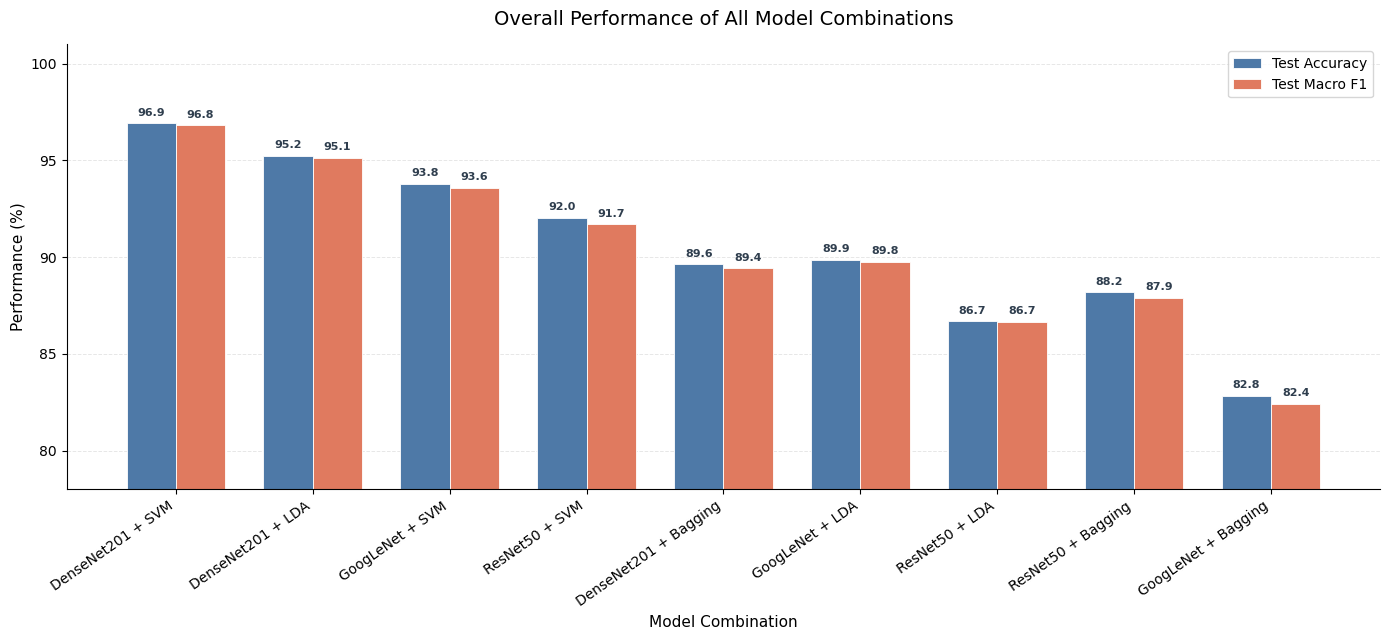

In [ ]:
overall_plot_data = all_results.copy()

x = np.arange(len(overall_plot_data))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(14, 6.5))


accuracy_colour = "#4E79A7"
macro_f1_colour = "#E07A5F"

accuracy_bars = ax.bar(
    x - bar_width / 2,
    overall_plot_data["Test Accuracy"] * 100,
    width=bar_width,
    label="Test Accuracy",
    color=accuracy_colour,
    edgecolor="white",
    linewidth=0.6,
)

macro_f1_bars = ax.bar(
    x + bar_width / 2,
    overall_plot_data["Test Macro F1"] * 100,
    width=bar_width,
    label="Test Macro F1",
    color=macro_f1_colour,
    edgecolor="white",
    linewidth=0.6,
)

ax.set_xticks(x)
ax.set_xticklabels(
    overall_plot_data["Model"],
    rotation=35,
    ha="right",
)

ax.set_xlabel("Model Combination", fontsize=11)
ax.set_ylabel("Performance (%)", fontsize=11)
ax.set_title(
    "Overall Performance of All Model Combinations",
    fontsize=14,
    pad=14,
)

ax.set_ylim(78, 101)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.3,
)

ax.set_axisbelow(True)

ax.bar_label(
    accuracy_bars,
    labels=[
        f"{value:.1f}"
        for value in overall_plot_data["Test Accuracy"] * 100
    ],
    padding=4,
    fontsize=8,
    fontweight="bold",
    color="#2F3E4E",
)

ax.bar_label(
    macro_f1_bars,
    labels=[
        f"{value:.1f}"
        for value in overall_plot_data["Test Macro F1"] * 100
    ],
    padding=4,
    fontsize=8,
    fontweight="bold",
    color="#2F3E4E",
)

ax.legend(
    loc="upper right",
    frameon=True,
    fontsize=10,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "overall_model_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### Classifier Comparison

To evaluate the effect of classifier choice, the test performance of SVM,
LDA and Bagging was averaged across DenseNet201, GoogLeNet and ResNet50.

This comparison examines whether the classifier ranking remained consistent
when different CNN feature extractors were used.

,Classifier,Mean_Test_Accuracy,Mean_Test_Macro_F1
0,SVM,0.9425,0.9404
1,LDA,0.9060,0.9052
2,Bagging,0.8688,0.8659


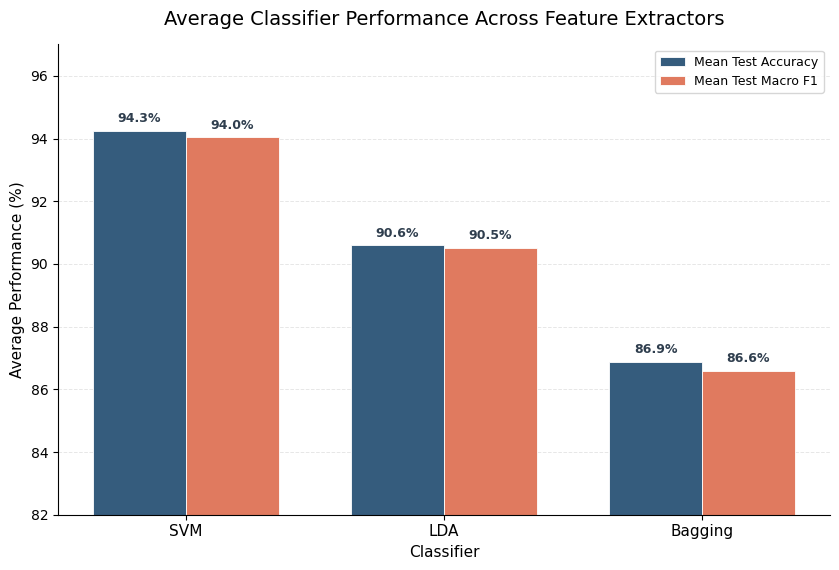

In [ ]:
classifier_plot_data = (
    all_results
    .groupby(
        "Classifier",
        as_index=False,
    )
    .agg(
        Mean_Test_Accuracy=("Test Accuracy", "mean"),
        Mean_Test_Macro_F1=("Test Macro F1", "mean"),
    )
)

classifier_order = ["SVM", "LDA", "Bagging"]

classifier_plot_data["Classifier"] = pd.Categorical(
    classifier_plot_data["Classifier"],
    categories=classifier_order,
    ordered=True,
)

classifier_plot_data = (
    classifier_plot_data
    .sort_values("Classifier")
    .reset_index(drop=True)
)

display(
    classifier_plot_data.style.format(
        {
            "Mean_Test_Accuracy": "{:.4f}",
            "Mean_Test_Macro_F1": "{:.4f}",
        }
    )
)

x = np.arange(len(classifier_plot_data))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(8.5, 5.8))

accuracy_colour = "#355C7D"
macro_f1_colour = "#E07A5F"

accuracy_bars = ax.bar(
    x - bar_width / 2,
    classifier_plot_data["Mean_Test_Accuracy"] * 100,
    width=bar_width,
    label="Mean Test Accuracy",
    color=accuracy_colour,
    edgecolor="white",
    linewidth=0.6,
)

macro_f1_bars = ax.bar(
    x + bar_width / 2,
    classifier_plot_data["Mean_Test_Macro_F1"] * 100,
    width=bar_width,
    label="Mean Test Macro F1",
    color=macro_f1_colour,
    edgecolor="white",
    linewidth=0.6,
)

ax.set_xticks(x)
ax.set_xticklabels(
    classifier_plot_data["Classifier"],
    fontsize=11,
)

ax.set_xlabel("Classifier", fontsize=11)
ax.set_ylabel("Average Performance (%)", fontsize=11)

ax.set_title(
    "Average Classifier Performance Across Feature Extractors",
    fontsize=14,
    pad=14,
)

ax.set_ylim(82, 97)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.3,
)

ax.set_axisbelow(True)

ax.bar_label(
    accuracy_bars,
    labels=[
        f"{value:.1f}%"
        for value in classifier_plot_data["Mean_Test_Accuracy"] * 100
    ],
    padding=4,
    fontsize=9,
    fontweight="bold",
    color="#2F3E4E",
)

ax.bar_label(
    macro_f1_bars,
    labels=[
        f"{value:.1f}%"
        for value in classifier_plot_data["Mean_Test_Macro_F1"] * 100
    ],
    padding=4,
    fontsize=9,
    fontweight="bold",
    color="#2F3E4E",
)

ax.legend(
    loc="upper right",
    frameon=True,
    fontsize=9,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "average_classifier_performance.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### Best Model Analysis: DenseNet201 + SVM

DenseNet201 with SVM was selected as the best model because it achieved the
highest validation Macro F1 score among the nine model combinations. The test
set was then used for the final class-level evaluation.

The following analysis examines its normalised confusion matrix, per-class
performance, common misclassification pairs, and the distribution of
different error types.

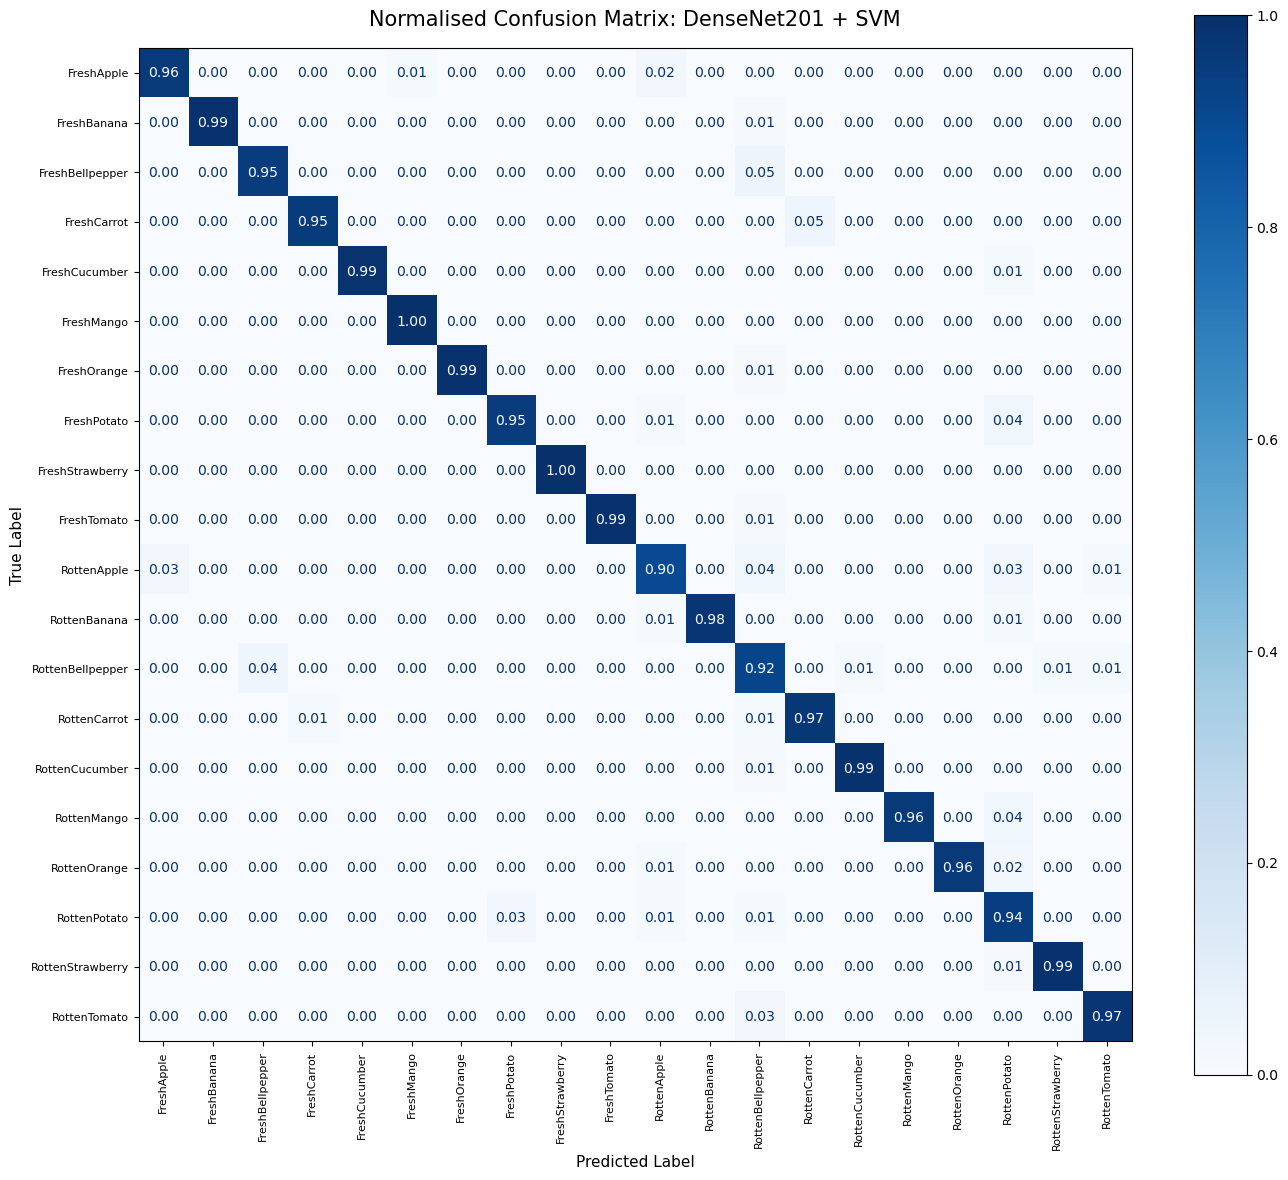

In [ ]:
best_test_predictions = densenet_predictions["svm_test_pred"]

assert len(best_test_predictions) == len(y_test)


try:
    class_names = list(train_dataset.classes)
except NameError:
    class_names = [
        "FreshApple",
        "FreshBanana",
        "FreshBellpepper",
        "FreshCarrot",
        "FreshCucumber",
        "FreshMango",
        "FreshOrange",
        "FreshPotato",
        "FreshStrawberry",
        "FreshTomato",
        "RottenApple",
        "RottenBanana",
        "RottenBellpepper",
        "RottenCarrot",
        "RottenCucumber",
        "RottenMango",
        "RottenOrange",
        "RottenPotato",
        "RottenStrawberry",
        "RottenTomato",
    ]

assert len(class_names) == 20

normalised_cm = confusion_matrix(
    y_test,
    best_test_predictions,
    labels=np.arange(len(class_names)),
    normalize="true",
)

fig, ax = plt.subplots(figsize=(14, 12))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=normalised_cm,
    display_labels=class_names,
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    colorbar=True,
)

ax.set_title(
    "Normalised Confusion Matrix: DenseNet201 + SVM",
    fontsize=15,
    pad=16,
)

ax.set_xlabel("Predicted Label", fontsize=11)
ax.set_ylabel("True Label", fontsize=11)

plt.setp(
    ax.get_xticklabels(),
    rotation=90,
    ha="center",
    fontsize=8,
)

plt.setp(
    ax.get_yticklabels(),
    fontsize=8,
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "densenet201_svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [ ]:
class_report = classification_report(
    y_test,
    best_test_predictions,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

per_class_results = pd.DataFrame(
    {
        "Class": class_names,
        "Precision": [
            class_report[class_name]["precision"]
            for class_name in class_names
        ],
        "Recall": [
            class_report[class_name]["recall"]
            for class_name in class_names
        ],
        "F1": [
            class_report[class_name]["f1-score"]
            for class_name in class_names
        ],
        "Support": [
            int(class_report[class_name]["support"])
            for class_name in class_names
        ],
    }
)


# Display all 20 classes
display(
    per_class_results.style.format(
        {
            "Precision": "{:.4f}",
            "Recall": "{:.4f}",
            "F1": "{:.4f}",
            "Support": "{:.0f}",
        }
    )
)


# Identify the five lowest-performing classes
lowest_five_classes = (
    per_class_results
    .sort_values(
        by="F1",
        ascending=True,
    )
    .head(5)
    .reset_index(drop=True)
)

print("Five lowest-performing classes:")

display(
    lowest_five_classes.style.format(
        {
            "Precision": "{:.4f}",
            "Recall": "{:.4f}",
            "F1": "{:.4f}",
            "Support": "{:.0f}",
        }
    )
)

,Class,Precision,Recall,F1,Support
0,FreshApple,0.9756,0.9639,0.9697,83
1,FreshBanana,1.0000,0.9891,0.9945,92
2,FreshBellpepper,0.9639,0.9524,0.9581,84
3,FreshCarrot,0.9880,0.9535,0.9704,86
4,FreshCucumber,1.0000,0.9857,0.9928,70
5,FreshMango,0.9891,1.0000,0.9945,91
6,FreshOrange,1.0000,0.9888,0.9944,89
7,FreshPotato,0.9750,0.9512,0.9630,82
8,FreshStrawberry,1.0000,1.0000,1.0000,86
9,FreshTomato,1.0000,0.9889,0.9944,90


Five lowest-performing classes:


,Class,Precision,Recall,F1,Support
0,RottenBellpepper,0.8235,0.9211,0.8696,76
1,RottenPotato,0.8395,0.9444,0.8889,72
2,RottenApple,0.9231,0.9000,0.9114,80
3,FreshBellpepper,0.9639,0.9524,0.9581,84
4,RottenCarrot,0.9452,0.9718,0.9583,71


In [ ]:
raw_cm = confusion_matrix(
    y_test,
    best_test_predictions,
    labels=np.arange(len(class_names)),
)

confusion_rows = []

for true_index in range(len(class_names)):
    for predicted_index in range(len(class_names)):
        if true_index == predicted_index:
            continue

        error_count = raw_cm[true_index, predicted_index]

        if error_count > 0:
            confusion_rows.append(
                {
                    "True Class": class_names[true_index],
                    "Predicted Class": class_names[predicted_index],
                    "Error Count": int(error_count),
                }
            )

confusion_pairs = (
    pd.DataFrame(confusion_rows)
    .sort_values(
        by="Error Count",
        ascending=False,
    )
    .reset_index(drop=True)
)

print("Most common misclassification pairs:")

display(
    confusion_pairs.head(10).style.format(
        {
            "Error Count": "{:.0f}",
        }
    )
)

Most common misclassification pairs:


,True Class,Predicted Class,Error Count
0,FreshBellpepper,RottenBellpepper,4
1,FreshCarrot,RottenCarrot,4
2,FreshPotato,RottenPotato,3
3,RottenApple,RottenBellpepper,3
4,RottenBellpepper,FreshBellpepper,3
5,RottenMango,RottenPotato,3
6,RottenApple,RottenPotato,2
7,RottenPotato,FreshPotato,2
8,RottenOrange,RottenPotato,2
9,RottenApple,FreshApple,2


### Fresh and Rotten Class Performance

To examine whether freshness condition affected classification performance,
the per-class results were grouped into fresh and rotten categories.

For each CNN feature extractor, the mean precision, recall and F1 score were
calculated separately for the ten fresh classes and the ten rotten classes.
SVM predictions were used because SVM was the strongest classifier for all
three feature extractors.

,Feature Extractor,Freshness,Mean_Precision,Mean_Recall,Mean_F1
0,DenseNet201,Fresh,0.9892,0.9773,0.9832
1,DenseNet201,Rotten,0.9484,0.9593,0.9531
2,GoogLeNet,Fresh,0.9686,0.9680,0.9681
3,GoogLeNet,Rotten,0.9065,0.9038,0.9039
4,ResNet50,Fresh,0.9564,0.9530,0.9545
5,ResNet50,Rotten,0.8805,0.8803,0.8797


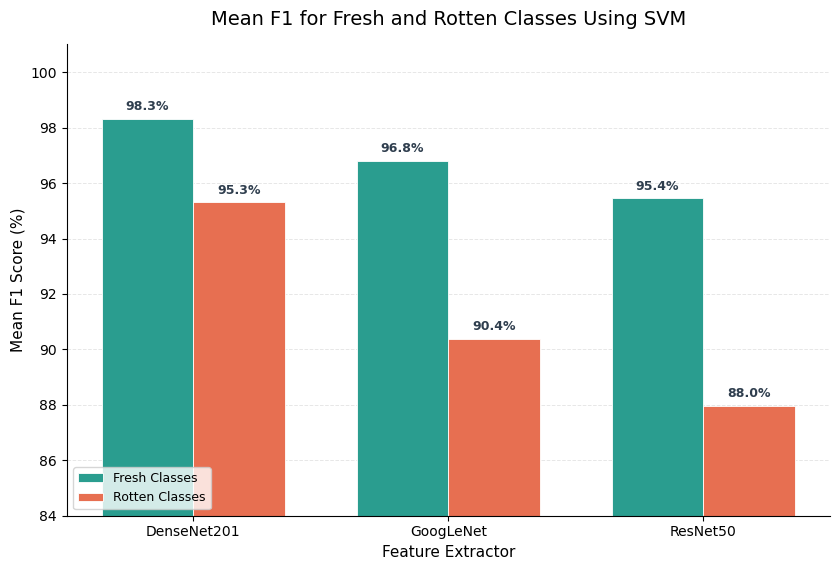

In [ ]:
svm_prediction_sets = {
    "DenseNet201": densenet_predictions["svm_test_pred"],
    "GoogLeNet": googlenet_predictions["svm_test_pred"],
    "ResNet50": resnet_predictions["svm_test_pred"],
}

freshness_rows = []

for feature_extractor, predictions in svm_prediction_sets.items():

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test,
        predictions,
        labels=np.arange(len(class_names)),
        zero_division=0,
    )

    for class_index, class_name in enumerate(class_names):

        freshness_group = (
            "Fresh"
            if class_name.startswith("Fresh")
            else "Rotten"
        )

        freshness_rows.append(
            {
                "Feature Extractor": feature_extractor,
                "Class": class_name,
                "Freshness": freshness_group,
                "Precision": precision[class_index],
                "Recall": recall[class_index],
                "F1": f1[class_index],
                "Support": int(support[class_index]),
            }
        )


svm_per_class_results = pd.DataFrame(freshness_rows)

freshness_summary = (
    svm_per_class_results
    .groupby(
        ["Feature Extractor", "Freshness"],
        as_index=False,
    )
    .agg(
        Mean_Precision=("Precision", "mean"),
        Mean_Recall=("Recall", "mean"),
        Mean_F1=("F1", "mean"),
    )
)


extractor_order = [
    "DenseNet201",
    "GoogLeNet",
    "ResNet50",
]

freshness_summary["Feature Extractor"] = pd.Categorical(
    freshness_summary["Feature Extractor"],
    categories=extractor_order,
    ordered=True,
)

freshness_summary = (
    freshness_summary
    .sort_values(
        ["Feature Extractor", "Freshness"]
    )
    .reset_index(drop=True)
)


display(
    freshness_summary.style.format(
        {
            "Mean_Precision": "{:.4f}",
            "Mean_Recall": "{:.4f}",
            "Mean_F1": "{:.4f}",
        }
    )
)

freshness_plot_data = (
    freshness_summary
    .pivot(
        index="Feature Extractor",
        columns="Freshness",
        values="Mean_F1",
    )
    .reindex(extractor_order)
)

x = np.arange(len(freshness_plot_data))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(8.5, 5.8))

fresh_colour = "#2A9D8F"
rotten_colour = "#E76F51"

fresh_bars = ax.bar(
    x - bar_width / 2,
    freshness_plot_data["Fresh"] * 100,
    width=bar_width,
    label="Fresh Classes",
    color=fresh_colour,
    edgecolor="white",
    linewidth=0.6,
)

rotten_bars = ax.bar(
    x + bar_width / 2,
    freshness_plot_data["Rotten"] * 100,
    width=bar_width,
    label="Rotten Classes",
    color=rotten_colour,
    edgecolor="white",
    linewidth=0.6,
)

ax.set_xticks(x)
ax.set_xticklabels(
    freshness_plot_data.index,
    fontsize=10,
)

ax.set_xlabel("Feature Extractor", fontsize=11)
ax.set_ylabel("Mean F1 Score (%)", fontsize=11)

ax.set_title(
    "Mean F1 for Fresh and Rotten Classes Using SVM",
    fontsize=14,
    pad=14,
)

ax.set_ylim(84, 101)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.3,
)

ax.set_axisbelow(True)

ax.bar_label(
    fresh_bars,
    labels=[
        f"{value:.1f}%"
        for value in freshness_plot_data["Fresh"] * 100
    ],
    padding=4,
    fontsize=9,
    fontweight="bold",
    color="#2F3E4E",
)

ax.bar_label(
    rotten_bars,
    labels=[
        f"{value:.1f}%"
        for value in freshness_plot_data["Rotten"] * 100
    ],
    padding=4,
    fontsize=9,
    fontweight="bold",
    color="#2F3E4E",
)

ax.legend(
    loc="lower left",
    frameon=True,
    fontsize=9,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "svm_fresh_vs_rotten_f1.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### Error-Type Analysis

The errors produced by DenseNet201 with SVM were divided into food-type
errors, freshness errors, and errors involving both components.

,Error Type,Error Count,Percentage
0,Food-type error,25,49.02%
1,Freshness error,21,41.18%
2,Food-type and freshness error,5,9.80%


Correct predictions: 1608
Incorrect predictions: 51


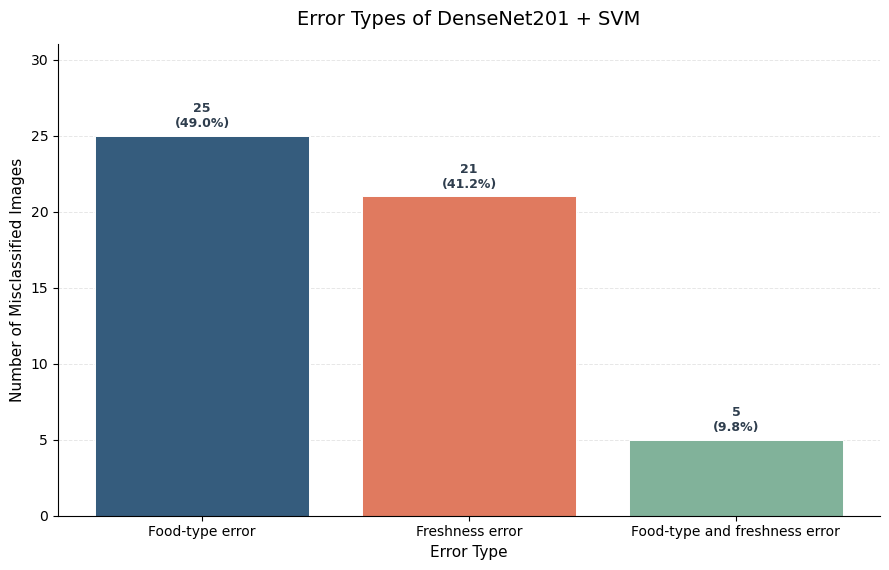

In [ ]:
def split_class_name(class_name):
    if class_name.startswith("Fresh"):
        return "Fresh", class_name.replace("Fresh", "", 1)

    if class_name.startswith("Rotten"):
        return "Rotten", class_name.replace("Rotten", "", 1)

    raise ValueError(f"Unexpected class name: {class_name}")


error_rows = []

for true_label, predicted_label in zip(
    y_test,
    best_test_predictions,
):
    if true_label == predicted_label:
        continue

    true_class = class_names[int(true_label)]
    predicted_class = class_names[int(predicted_label)]

    true_freshness, true_food = split_class_name(true_class)
    predicted_freshness, predicted_food = split_class_name(
        predicted_class
    )

    if true_food == predicted_food:
        error_type = "Freshness error"
    elif true_freshness == predicted_freshness:
        error_type = "Food-type error"
    else:
        error_type = "Food-type and freshness error"

    error_rows.append(
        {
            "True Class": true_class,
            "Predicted Class": predicted_class,
            "Error Type": error_type,
        }
    )


error_details = pd.DataFrame(error_rows)

error_order = [
    "Food-type error",
    "Freshness error",
    "Food-type and freshness error",
]

error_summary = (
    error_details["Error Type"]
    .value_counts()
    .reindex(error_order, fill_value=0)
    .rename_axis("Error Type")
    .reset_index(name="Error Count")
)

error_summary["Percentage"] = (
    error_summary["Error Count"]
    / len(error_details)
    * 100
)


display(
    error_summary.style.format(
        {
            "Error Count": "{:.0f}",
            "Percentage": "{:.2f}%",
        }
    )
)

print("Correct predictions:", int((y_test == best_test_predictions).sum()))
print("Incorrect predictions:", len(error_details))


fig, ax = plt.subplots(figsize=(9, 5.8))

error_colours = [
    "#355C7D",
    "#E07A5F",
    "#81B29A",
]

bars = ax.bar(
    error_summary["Error Type"],
    error_summary["Error Count"],
    color=error_colours,
    edgecolor="white",
    linewidth=0.7,
)

ax.set_xlabel("Error Type", fontsize=11)
ax.set_ylabel("Number of Misclassified Images", fontsize=11)

ax.set_title(
    "Error Types of DenseNet201 + SVM",
    fontsize=14,
    pad=14,
)

ax.set_ylim(
    0,
    error_summary["Error Count"].max() + 6,
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.3,
)

ax.set_axisbelow(True)

ax.bar_label(
    bars,
    labels=[
        f"{count}\n({percentage:.1f}%)"
        for count, percentage in zip(
            error_summary["Error Count"],
            error_summary["Percentage"],
        )
    ],
    padding=4,
    fontsize=9,
    fontweight="bold",
    color="#2F3E4E",
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "densenet201_svm_error_types.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### Validation–Test Consistency

The validation and test Macro F1 scores were compared to examine whether the
relative performance of the nine model combinations remained stable across
the two evaluation splits.

In [ ]:
generalisation_results = all_results.copy()

generalisation_results["Test Rank"] = (
    generalisation_results["Test Macro F1"]
    .rank(
        method="min",
        ascending=False,
    )
    .astype(int)
)

generalisation_results["Macro F1 Difference"] = (
    generalisation_results["Test Macro F1"]
    - generalisation_results["Validation Macro F1"]
)

generalisation_results["Absolute Macro F1 Gap"] = (
    generalisation_results["Macro F1 Difference"].abs()
)

generalisation_results["Rank Change"] = (
    generalisation_results["Test Rank"]
    - generalisation_results["Validation Rank"]
)

generalisation_display = (
    generalisation_results[
        [
            "Model",
            "Validation Rank",
            "Test Rank",
            "Rank Change",
            "Validation Macro F1",
            "Test Macro F1",
            "Macro F1 Difference",
            "Absolute Macro F1 Gap",
        ]
    ]
    .sort_values("Validation Rank")
    .reset_index(drop=True)
)

display(
    generalisation_display.style.format(
        {
            "Validation Macro F1": "{:.4f}",
            "Test Macro F1": "{:.4f}",
            "Macro F1 Difference": "{:+.4f}",
            "Absolute Macro F1 Gap": "{:.4f}",
        }
    )
)

,Model,Validation Rank,Test Rank,Rank Change,Validation Macro F1,Test Macro F1,Macro F1 Difference,Absolute Macro F1 Gap
0,DenseNet201 + SVM,1,1,0,0.9566,0.9681,+0.0116,0.0116
1,DenseNet201 + LDA,2,2,0,0.9427,0.9514,+0.0087,0.0087
2,GoogLeNet + SVM,3,3,0,0.9280,0.9360,+0.0080,0.0080
3,ResNet50 + SVM,4,4,0,0.9046,0.9171,+0.0125,0.0125
4,DenseNet201 + Bagging,5,6,1,0.8840,0.8943,+0.0103,0.0103
5,GoogLeNet + LDA,6,5,-1,0.8697,0.8975,+0.0279,0.0279
6,ResNet50 + LDA,7,8,1,0.8650,0.8666,+0.0016,0.0016
7,ResNet50 + Bagging,8,7,-1,0.8593,0.8790,+0.0197,0.0197
8,GoogLeNet + Bagging,9,9,0,0.8103,0.8243,+0.0140,0.0140
